Data Clean Up document from 2022:

https://drive.google.com/drive/folders/1-m-4NOTqvHZlHqPQW37XGDqIVfp1zfRG?usp=sharing

# Comprehensive:

In [1]:
# RUN THIS AT END TO SAVE OUTPUT

with open(jsonpath, 'w') as f:
    json.dump(jsonout, f, indent=4)

NameError: name 'jsonpath' is not defined

### TO DO:

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
#1
# Make sure you copy the folder to your personal drive (or create a shortcut <- easier)

#TO DO - everything needed modifying is done here
# update to the semester if needed (check where the data is ON YOUR drive)

folder = "2024 Fall - Data/"
data_folder = "2019-2023 cleaned"

# Edit path based on where your data folder is
#for data read in
root_path = "/content/drive/My Drive/ECI Research/5. Datasets/"
path_to_data =  root_path+folder
GDP4_path = root_path+"2024 Fall - Data"

#TO DO: MODIFY T0 YOUR COUNTRY below
  # No need change elsewhere, unless stated otherwise
main_country = "Vietnam"

#TO DO: MODIFY YOUR COMPARABLE COUNTRIES HERE
  # make sure to include your main country (you modified already above)
comparable_countries = [main_country, 'Singapore', 'Malaysia', 'Philippines']

#emerging economies for SDV:
sdv_emerging_countries = ["China", "Singapore"]

#leading economies for SDV:
sdv_leading_countries = ['France', 'Greece', 'Portugal']

#SDV's list - any possible note name changes
sdv_comparable_countries = [main_country, 'Greece', 'Poland', 'Portugal', 'France']

#path for sdv_and_sids folder:
#sdv_path = root_path + "/New_result_update/sdv_and_sids/"
sdv_path = root_path + "2019-2023 cleaned/2023clean.csv"

# Change to relevant years
begin_year = 2019
end_year = 2023


AUTO_REPORT_PATH = "/content/drive/My Drive/ECI Auto Report Demo"
os.makedirs(f"{AUTO_REPORT_PATH}/img", exist_ok=True)

category = "developed" #developed or emerging

jsonpath = f'{AUTO_REPORT_PATH}/{main_country}.json'

jsonout = {}

if os.path.exists(jsonpath):
      with open(jsonpath, 'r') as f:
        jsonout = json.load(f)

jsonout["[Country]"] = main_country
jsonout["[Category]"] = category
jsonout["[Start Year]"] = begin_year
jsonout["[End Year]"] = end_year

#### Import Packages

In [4]:
#3
# only run once - uncomment if needed

!pip install xlwt
!pip install -U kaleido==0.2.1 #Install the kaleido package for exporting images

#needed to downgrade plotly for kaleido to work; the code seems to run fine with the lower version,
#but let me know if we run into issues
!pip install plotly==5.3.1


In [5]:
#4
from google.colab import files # not needed for personal
import io
import os
from tqdm import tqdm
import csv

import statsmodels.api as sm
import statsmodels.formula.api as smf
import math
from sklearn.linear_model import LinearRegression

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
from scipy import linalg as LA
import operator
from xlwt import Workbook
import xlwt

#import plotly.express as px

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pickle

zzz=np.random.randint(1,100)

#### Import Data

In [6]:
#5
# Base path for the data - path_to_data = "drive/My Drive/ECI Research/5. Datasets/2023 Fall - Data/"

# Read input - CHECK DATA FOR RELEVANCE
#uploaded = files.upload()
#NZ created 2019-2022 cleaned folder
df1 = df = pd.read_csv(path_to_data+data_folder+'/2019clean.csv') #index_col=0)
df2 = pd.read_csv(path_to_data+data_folder+'/2020clean.csv')
df3 = pd.read_csv(path_to_data+data_folder+'/2021clean.csv')
df4 = pd.read_csv(path_to_data+ data_folder+'/2022clean.csv') #!!! added for new year - JZ
df5 = pd.read_csv(path_to_data+ data_folder+'/2023clean.csv') # added for 2023 - JZ

gdp_df = pd.read_csv(path_to_data+'GDP_2023.csv')
gdp_df = gdp_df.drop(columns=['Country Code', 'Series Name']).rename(columns={'Country Name': 'Country'})

In [7]:
# turns dataframe into matrix, cleans and checks data as well (nonzero values)
def df_to_matrix(dfa):
  raw_matrixa = dfa.to_numpy()
  matrixa = [list(dfa.columns)]

  for row in raw_matrixa:
    stripped=np.char.strip(np.array(row[1::]).astype(str),chars='_')
    if np.min(stripped.astype(float)) > 0: # decide whether or not to keep
      matrixa.append(list(row))

  return matrixa

dataframes = [df1, df2, df3, df4, df5, gdp_df] #!!! edited to add 2022 - JZ
mxlist = []
for data in dataframes:
    for i in range(len(data["Country"])):
      country_name = data["Country"][i]
      if country_name == "Plurinational State of Bolivia":
          data.loc[i, "Country"] = "Bolivia"
      elif country_name == 'Norway, Svalbard and Jan Mayen':
          data.loc[i, "Country"]  = 'Norway'
      elif country_name == 'Russian Federation':
          data.loc[i, "Country"]  = 'Russia'
      elif country_name == 'Korea, Rep.' or country_name == 'Republic of Korea':
          data.loc[i, "Country"] = 'South Korea'
      elif country_name == 'France, Monaco':
          data.loc[i, "Country"]  = 'France'
      elif country_name == 'Congo, Dem. Rep.' or country_name == 'Congo, Rep.':
          data.loc[i, "Country"]  = 'Congo'
      elif country_name == "Côte d'Ivoire":
          data.loc[i, "Country"]  = "Cote d'Ivoire"
      elif country_name == 'Bahamas, The':
          data.loc[i, "Country"]  =  'Bahamas'
      elif country_name == 'Yemen, Rep.':
          data.loc[i, "Country"]  =  'Yemen'
      elif country_name == 'Viet Nam':
          data.loc[i, "Country"]  =  'Vietnam'
      elif country_name  == 'USA, Puerto Rico and US Virgin Islands' or country_name =='United States':
          data.loc[i, "Country"]  =  'USA'
      elif country_name =="Albania":
          data.loc[i, "Country"]  =  'Albania'
    mxlist.append(df_to_matrix(data))

# to be consistent with naming -> used in ECI
matrix = mxlist[0] #2019
matrix2 = mxlist[1]
matrix3 = mxlist[2]
matrix4 = mxlist[3] #2022
matrix5 = mxlist[4] #2023

In [8]:
#7
# Find values that do not match
#mismatch_values = gdp_df[~gdp_df['Country'].isin(df1['Country'])]['Country']

# Display or use mismatch values as needed
#print("Mismatch values:", mismatch_values.tolist())
#print("Mismatch values:", mismatch_values)

all_countries_used = (
    comparable_countries +
    sdv_emerging_countries +
    sdv_leading_countries +
    sdv_comparable_countries
)

all_countries_used = list(set(all_countries_used))

# Print the resulting array
print("All country names used:")
print(all_countries_used)

bad_countries_used = [country for country in all_countries_used if country not in gdp_df['Country'].values]
print("Bad names in GDP file - pls fix if needed:")
print(bad_countries_used)


All country names used:
['Philippines', 'Malaysia', 'Greece', 'Vietnam', 'Poland', 'China', 'France', 'Singapore', 'Portugal']
Bad names in GDP file - pls fix if needed:
[]


In [9]:
# 9
# this is both finding missing data and making a dict for GDP
def find_missing_data(df):
    missing_data = []
    gdp_dict = {}

    for index, row in df.iterrows():
        country = row['Country']
        year_value_list =[]

         # Get last 4 years to analyze NA's
        for col in df.iloc[:, -4:]:

            if pd.isna(row[col]) or not pd.notna(pd.to_numeric(row[col], errors='coerce')):
                    missing_data.append((country, col))
            else:
                   year_value_list.append((col, row[col]))
        gdp_dict[country] = year_value_list

    missing_data_df = pd.DataFrame(missing_data, columns=['Country', 'Year'])
    return missing_data_df, gdp_dict

missing_data_df, gdp_range_dict = find_missing_data(gdp_df)
#print(missing_data_df)
#gdp_range_dict

In [10]:
# 10
gdp_df_filtered = gdp_df[['Country', '2019', '2020', '2021', '2022']] # updated - JZ

'''
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

print(gdp_df_filtered)

pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')
'''
#Use this block to update values if they are missing:
print(main_country, gdp_df_filtered.loc[gdp_df_filtered['Country'] == main_country, ['2019', '2020', '2021', '2022']].values[0]) # updated - JZ

# To change the value in OG dataframe:
# gdp_df.loc[gdp_df['Country Name'] == main_country, '2019'] = -100
# gdp_df.head()

Vietnam [3.34e+11 3.47e+11 3.66e+11 4.09e+11]


## ECI & PCI

MCP

In [11]:
#11
#compute mcp
#input is matrix, output is the original product and country lists, the MCP values, the product sums, and the country sums

def compute_mcp(matrix):
  product_list = matrix[0][1::]
  country_list = []
  for i in range(1,len(matrix)):
    country_list.append(matrix[i][0])

  country_sum = []
  for i in range(1,len(matrix)):
    stripped=np.char.strip(np.array(matrix[i][1::]).astype(str),chars='_')
    country_sum.append(np.sum(stripped.astype(float)))

  product_sum = []
  for i in range(1,len(matrix[0])):
    product = 0
    for j in range(1,len(matrix)):
        product += matrix[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcp = []

  for i in range (1,len(matrix)):
    country_row = []
    for j in range(1,len(matrix[i])):
      try:
        percentage = matrix[i][j]/country_sum[i-1]
      except:
        print(country_list[i-1])
      total_percentage = product_sum[j-1]/total_sum
      if percentage > total_percentage:
        country_row.append(1)
      else:
        country_row.append(0)
    mcp.append(country_row)

  return country_list,product_list,mcp,product_sum,country_sum

MCC

In [12]:
#12
#computes mcc from mcp
def compute_mcc(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcc = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp)):
      temp_sum = 0
      for k in range(0,len(mcp[0])):
        try:
          value = (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
          if np.isinf(value) or np.isnan(value):
            temp_sum += 0
          else:
            temp_sum += value
        except:
          pass
      country_row.append(temp_sum)
    mcc.append(country_row)
  return mcc

MPP

In [13]:
#13
# compute mpp from mcp
def compute_mpp(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mpp = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += (mcp[k][i] * mcp2[k][j]/(country_sum[k]*product_sum[i]))
        except:
          pass
      product_row.append(temp_sum)
    mpp.append(product_row)
  return mpp

ECI

In [14]:
#14
#compute ECI from mcc
def compute_eci(mcc):
  mcc = np.array(mcc)

  e_vals, e_vecs = LA.eig(mcc)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  eci = []
  if vector[0] < 0:
    for item in vector:
      eci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      eci.append((-item+np.mean(vector))/np.std(vector))
  return eci

PCI

In [15]:
#15
#compute PCI from mpp
def compute_pci(mpp):
  mpp = np.array(mpp)
  e_vals, e_vecs = LA.eig(mpp)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  pci = []
  if vector[len(vector)-2] > 0:
    for item in vector:
      pci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      pci.append((-item+np.mean(vector))/np.std(vector))
  return pci


In [16]:
#16
#matrix is for year 2019
#matrix2 is for year 2020
#FOR THIS UPDATE ONLY USE YEAR 2021 (matrix3)
country_list,product_list,mcp,product_sum,country_sum = compute_mcp(matrix3)
country_list_last_year,product_list_last_year,mcp_last_year,product_sum_last_year,country_sum_last_year = compute_mcp(matrix3)

mcc = compute_mcc(mcp)
mpp = compute_mpp(mcp)

mcc_last_year = compute_mcc(mcp_last_year)
mpp_last_year = compute_mpp(mcp_last_year)

eci = compute_eci(mcc)
pci = compute_pci(mpp)

eci_last_year = compute_eci(mcc_last_year)
pci_last_year = compute_pci(mpp_last_year)

#check ECI
eci_dict = {}
for i in range(len(country_list)):
  eci_dict[country_list[i]]=eci[i]
sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))

#check PCI
pci_dict = {}
for i in range(len(product_list)):
  pci_dict[product_list[i]]=pci[i]
sorted_pci_dict = sorted(pci_dict.items(), key=operator.itemgetter(1))

#check ECI
eci_dict_last_year = {}
for i in range(len(country_list_last_year)):
  eci_dict_last_year[country_list_last_year[i]]=eci_last_year[i]
sorted_eci_dict_last_year = sorted(eci_dict_last_year.items(), key=operator.itemgetter(1))

# Tester if needed:
# print(sorted_eci_dict)
# for item in sorted_pci_dict:
 # print(item)

## Section 2: Graphs (ECI and GDP)

In [17]:
#17
##Changing matrices into dictionary format
def get_eci_dict(mat):
  country_list,product_list,mcp,product_sum,country_sum = compute_mcp(mat)
  mcc = compute_mcc(mcp)
  eci = compute_eci(mcc)
  eci_dict = {}
  for i in range(len(country_list)):
    eci_dict[country_list[i]]=eci[i]
  sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))
  return sorted_eci_dict

In [18]:
#18
## Changing matrices into dictionary format
# matrix3 is for 2021
matrix3 = df_to_matrix(df3)
#print(matrix3[3])
matrix3[18][3] = matrix3[18][3] *1

eci_2019 = get_eci_dict(matrix)
eci_2020 = get_eci_dict(matrix2)
eci_2021 = get_eci_dict(matrix3)
eci_2022 = get_eci_dict(matrix4) #!!! 2022 addition - JZ
eci_2023 = get_eci_dict(matrix5)

In [19]:
#19
from collections import defaultdict
eci_list = [eci_2019, eci_2020, eci_2021, eci_2022, eci_2023] # updated - JZ
eci_19to21_dict = defaultdict(list)
i = 0
for li in eci_list:
  for entry in li:
    eci_19to21_dict[entry[0]].append((2019+i, entry[1]))
  i += 1

#this is a test for your country (you modified above)
# eci_19to21_dict[main_country]

#create a dataframe to export the data into a document
df = pd.DataFrame(eci_19to21_dict[main_country], columns=['Year', 'ECI'])

#make file name easily changeable
year_name = '_eci_'+ str(begin_year)[2:] + 'to' + str(end_year)[2:] + '_dict'

#export to text document
filename = main_country + year_name + '.txt'
with open(filename, 'w') as f:
  f.write(df.to_string())

#export to excel
filename = main_country + year_name + '.xlsx'
df.to_excel(filename, index=False)

Average Annual Growth Rate

In [20]:
#20
#calculates average annual growth rate
def aagrate(nums):
  tot = 0
  i = 0
  while i < len(nums) - 1:
    tot += (((nums[i+1]-nums[i])/nums[i]) * 100)
    i += 1
  return tot/len(nums)

GDP Peer Comparison Graph

In [21]:
#21
y_values = [float(x[1]) / (10 ** 9) for x in gdp_range_dict[country_name]]

#x = int(x_values)
y_values

[21.509698406, 28.371238666, 20.678055598, 35.2]

[2020, 2021, 2022, 2023]
[2020, 2021, 2022, 2023]
[2020, 2021, 2022, 2023]
[2020, 2021, 2022, 2023]


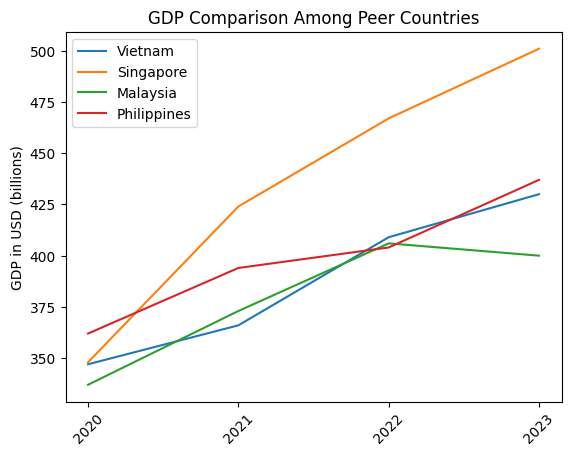

In [22]:
#22
# MD FIXed
# to fix - names:
def gdp_comparison_graph(cnames):
    from matplotlib.ticker import MultipleLocator
    fig, ax = plt.subplots()

    #FIX - naming fixes
    for country_name in cnames:

        label = country_name

        x_values = [int(x[0]) for x in gdp_range_dict[country_name]]
        y_values = [float(x[1]) / (10 ** 9) for x in gdp_range_dict[country_name]]
        print(x_values)

        # Create the plot
        max_ticks = 4  # You can adjust this number as needed
        #ax.xaxis.set_major_locator(plt.MaxNLocator(max_ticks))
        ax.xaxis.set_major_locator(MultipleLocator(1))
        # Ensure that tick marks on the x-axis are integers
        #ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x_values, _: int(x_values)))
        ax.tick_params(axis='x', rotation=45)
        ax.plot(x_values, y_values, label=label)

    plt.ylabel('GDP in USD (billions)')
    plt.legend()
    plt.title('GDP Comparison Among Peer Countries')

    # Export the file as a downloadable png
    plt.savefig(f'{AUTO_REPORT_PATH}/img/kix.2h1zoxev3wer.png')

    # Show the plot
    plt.show()

    return plt

plt = gdp_comparison_graph(comparable_countries)

# Show the plot
plt.show()

In [23]:
# TO FIX - merge with above fixing_missing_values
#to deal with NA values
gdp_range_dict['United Arab Emirates'][2] = (2021, 415000000000)

In [24]:
#23
# TO FIX - not CAGR in the file




#these cutoffs should depend on category.
#GDP growth expectations are different for emerging vs developed
def printgdps(cns):
   allgdps = []
   maingdp = None
   for cn in cns:
     print(cn)

     if cn == main_country:
      grwth = round(aagrate([x[1] for x in gdp_range_dict[cn]]),2)
      jsonout["[GDP growth rate]"] = str(grwth)
      if grwth > 3:
        jsonout["[GDP growth quality]"] = "high"
      elif grwth > 1:
        jsonout["[GDP growth quality]"] = "moderate"
      else:
        jsonout["[GDP growth quality]"] = "low"
      print(grwth)
      maingdp = grwth
     else:
      grwth = round(aagrate([x[1] for x in gdp_range_dict[cn]]),2)
     allgdps.append(grwth)

   allgdps.sort()
   pctile = (allgdps.index(maingdp))/float(len(allgdps))
   if pctile > 0.66:
     jsonout["[Relative GDP growth quality]"] = "high"
   elif pctile > 0.33:
     jsonout["[Relative GDP growth quality]"] = "moderate"
   else:
     jsonout["[Relative GDP growth quality]"] = "low"

gdp_percents = printgdps(comparable_countries)
gdp_percents

Vietnam
5.59
Singapore
Malaysia
Philippines


In [25]:
#24
# TO FIX - not CAGR in the file

gdp_percents = printgdps(comparable_countries) ## ADD THIS
#saves the output in a txt file
with open('comparable_countries_gdp.txt', 'w') as f:

    for cn in comparable_countries:
        f.write(cn + '\n')
        f.write(str(round(aagrate([x[1] for x in gdp_range_dict[cn]]),2)) + '\n')
        #write GDP %

Vietnam
5.59
Singapore
Malaysia
Philippines


ECI Peer Comparison Graph

In [26]:
#25
## UPDATED - MD
from matplotlib.ticker import MultipleLocator
def eci_comparison_graph(cnames):
  fig, ax = plt.subplots()
  finals = 0
  count = 0
  main_country_eci = eci_19to21_dict[main_country][-1][1]
  #cleanup country names
  for country_name in cnames:
    if country_name == 'Plurinational State of Bolivia':
      label = 'Bolivia'
    elif country_name == 'Norway, Svalbard and Jan Mayen':
      label = 'Norway'
    elif country_name == 'Russian Federation':
      label = 'Russia'
    elif country_name == 'France':
      country_name = 'France, Monaco'
      label = 'France'
    else:
      label = country_name

    x_values = [int(x[0]) for x in eci_19to21_dict[country_name]]
    y_values = [x[1] for x in eci_19to21_dict[country_name]]

    if len(x_values):
      finals += y_values[-1]
      count += 1

    ax.xaxis.set_major_locator(MultipleLocator(1))
    # Ensure that tick marks on the x-axis are integers
    #ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x_values, _: int(x_values)))
    ax.tick_params(axis='x', rotation=45)
    # Create the plot
    ax.plot(x_values, y_values, label = label)

    # Set the tick labels to custom values, '' added for consistent labeling

    # print(eci_19to21_dict[country_name])

  plt.ylabel('ECI')
  plt.legend()
  plt.title('ECI Comparison Among Peer Countries')
  #saves figure as png
  plt.savefig(f'{AUTO_REPORT_PATH}/img/kix.we5usefgy5tx' + '.png')
  plt.show()
  avg = finals / count

  if main_country_eci > avg:
    jsonout["[ECI growth quality]"] = "increased"
  elif main_country_eci > avg/2:
    jsonout["[ECI growth quality]"] = "similar"
  else:
    jsonout["[ECI growth quality]"] = "decreased"


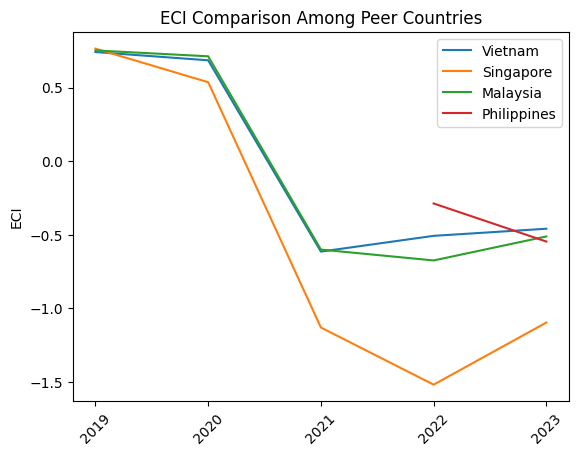

In [27]:
eci_comparison_graph(comparable_countries)

In [28]:
#26

# this is eci_change
#TO FIX - country names + more descriptive file?
#saves output as txt file


with open('comparable_countries_eci_19to21_dict.txt', 'w') as f:
    for country_name in comparable_countries:
        if country_name == 'France':
            country_name = 'France, Monaco'
        elif country_name == "Korea, Rep.":
            country_name = 'Republic of Korea'
        f.write(country_name + '\n')
        f.write(str(round((eci_19to21_dict[country_name][len(eci_19to21_dict[country_name])-1][1]-eci_19to21_dict[country_name][0][1])/abs(eci_19to21_dict[country_name][0][1]) * 100,2)) + '\n')




In [29]:
#27
## To FIX
def eci_change(cns):
  for country_name in cns:
    if country_name == 'France':
      country_name = 'France, Monaco'
    elif country_name == "Korea, Rep.":
      country_name = 'Republic of Korea'

    print(country_name)
    print(round((eci_19to21_dict[country_name][len(eci_19to21_dict[country_name])-1][1]-eci_19to21_dict[country_name][0][1])/abs(eci_19to21_dict[country_name][0][1]) * 100,2))

#ok to double print output here

eci_change(comparable_countries)

Vietnam
-161.96
Singapore
-243.49
Malaysia
-168.04
Philippines
-89.96


GDP Growth and ECI Trend Graph

In [30]:
# #29
# ## ## UPDATED - MD:
# def gdp_and_eci_graph(country_name):
#   if country_name=='Vietnam': #not sure if some other names should be changed too
#     country_name='Viet Nam'
#   elif country_name == 'France':
#     country_name = 'France, Monaco'

#   fig, ax1 = plt.subplots()

#   ax1.set_ylabel('GDP in USD (billions)')
#   x_values = [x[0] for x in gdp_range_dict[country_name]]
#   y_values = [float(x[1])/(10**9) for x in gdp_range_dict[country_name]]
#   # Create the plot
#   ax1.xaxis.set_major_locator(MultipleLocator(1))
#     # Ensure that tick marks on the x-axis are integers
#     #ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x_values, _: int(x_values)))
#   ax1.tick_params(axis='x', rotation=45)
#   ax1.plot(x_values, y_values, color = 'red', label='GDP')

#   # Set the tick labels to custom values, '' added for consistent labeling
#   #!!! function to label graph years consistent w/ x_values - JZ
#   """ ticklabels = ['', x_values[0]]
#     for x in x_values[1:]:
#       ticklabels.append('')
#       ticklabels.append('')
#       ticklabels.append('')
#       ticklabels.append('x')
#     ticklabels.append('')
#     ax1.set_xticklabels(ticklabels)"""
#   #ax1.set_xticklabels(['', '2019','','','','2020','','','','2021',''])
#   ax1.legend(loc = 'upper left')

#   ax2 = ax1.twinx()
#   ax2.set_ylabel('ECI')
#   #!!! EDITED below because num of ECI values != num of GDP values b/c data
#   #!!! only using years in both ECI and GDP - JZ
#   def Convert(tup, di):
#     di = dict(tup)
#     return di
#   dictionary = {}
#   country_dict = (Convert(eci_19to21_dict[main_country], dictionary))
#   ax2.plot(x_values,[country_dict[int(x)] for x in x_values], color = 'blue', label='ECI')

#   #ax2.plot(x_values,[x[1] for x in eci_19to21_dict[country_name]], color = 'blue', label='ECI')
#   ax2.legend(loc = 'upper right')
#   plt.title('GDP and ECI Trend for ' + country_name)
#   plt.savefig('drive/My Drive/ECI Auto Report Test/img/kix.kwwogf42gcjl.png')
#   plt.show()



import json
import os

def gdp_and_eci_graph(country_name):


  fig, ax1 = plt.subplots()

  ax1.set_ylabel('GDP in USD (billions)')
  x_values = [x[0] for x in gdp_range_dict[country_name]]
  years = [int(x) for x in x_values]
  start_year, end_year = min(years), max(years)

  y_values = [float(x[1])/(10**9) for x in gdp_range_dict[country_name]]

  ax1.xaxis.set_major_locator(MultipleLocator(1))
  ax1.tick_params(axis='x', rotation=45)
  ax1.plot(x_values, y_values, color='red', label='GDP')
  ax1.legend(loc='upper left')

  ax2 = ax1.twinx()
  ax2.set_ylabel('ECI')

  def Convert(tup, di):
    di = dict(tup)
    return di

  dictionary = {}
  country_dict = (Convert(eci_19to21_dict[main_country], dictionary))
  ax2.plot(x_values, [country_dict[int(x)] for x in x_values], color='blue', label='ECI')
  ax2.legend(loc='upper right')

  plt.title('GDP and ECI Trend for ' + country_name)

  #AI code is fine but at least run it to see if it works...


  # --- save image (as you already do) ---
  plt.savefig(f'{AUTO_REPORT_PATH}/img/kix.kwwogf42gcjl.png')
  plt.show()

  #All these tags are already in use

  # --- NEW: write tags JSON used by Apps Script ---
  # tags = {
  #   "[Start Year]": str(start_year),
  #   "[End Year]": str(end_year),
  #   "[Country]": country_name
  # }

  # tags_path = "drive/My Drive/ECI Auto Report Test/tags.json"  # pick your actual path
  # os.makedirs(os.path.dirname(tags_path), exist_ok=True)
  # with open(tags_path, "w", encoding="utf-8") as f:
  #   json.dump(tags, f, ensure_ascii=False, indent=2)

  return tags


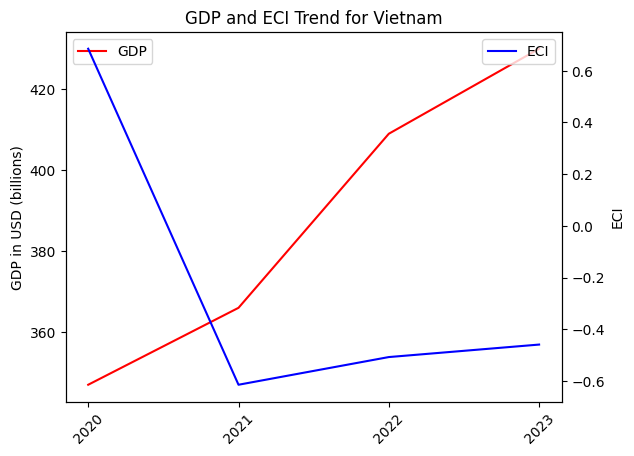

NameError: name 'tags' is not defined

In [32]:
tags = gdp_and_eci_graph(main_country)
# jsonout.update(tags)


## Proximity, Distance, and RID

Proximity

In [33]:
#30
def compute_proximity(mcp,product_sum):
  proximity = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += mcp[k][i] * mcp[k][j]
        except:
          pass
      p0 = product_sum[i]
      p1 = product_sum[j]
      if p0 < p1:
        large = p1
      else:
        large = p0
      product_row.append(temp_sum/large)
    proximity.append(product_row)
  return proximity

Distance

In [34]:
#31
#compute distance
def compute_distance(mcp,proximity):
  distance = []
  for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
      sum1 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum1 += mcp[i][k]*proximity[j][k]
          except:
            pass
      sum2 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum2 += proximity[j][k]
          except:
            pass
      product_row.append(1-sum1/sum2)
    distance.append(product_row)
  return distance

RID

In [35]:
#32
def compute_adi(df_middle,country_list,distance):
  raw_matrix = df_middle.to_numpy()
  matrix = [list(df_middle.columns)]
  for row in raw_matrix:
    if sum(row[1::]) > 0:
      matrix.append(list(row))

  country_list2,product_list2,mcp2,product_sum2,country_sum2 = compute_mcp(matrix)
  proximity2 = compute_proximity(mcp2,product_sum2)
  distance2 = compute_distance(mcp2,proximity2)

  adi = {}
  for i in range(len(country_list)):
    for j in range(len(country_list2)):
      if country_list[i] == country_list2[j]:
        adi[country_list[i]] = np.array(distance2[j]) - np.array(distance[i])
  return adi, country_list2,product_list2

In [36]:
#33
# 18 is equivalent to year 2021
proximity = compute_proximity(mcp,product_sum)
proximity_last_year = compute_proximity(mcp_last_year,product_sum_last_year)

distance = compute_distance(mcp,proximity)
#!!! df_middle changed to df2 because df2 corresponds to df_middle in All Code_v02 - JZ
adi, country_list2,product_list2  = compute_adi(df2,country_list,distance)

In [37]:
#34
# UPDATED
df_ = pd.DataFrame()
df_['Category'] = product_list_last_year
df_['RID'] = adi[main_country]
df_.sort_values(by="RID", inplace = True)

# Export the DataFrame to an Excel file
filename = main_country + '_RID.xlsx'
df_.to_excel(filename, index=True)
print('ADI results saved to', filename)

ADI results saved to Vietnam_RID.xlsx


In [38]:
!pip install dataframe_image

In [39]:
import dataframe_image as dfi

def style_alternate_rows(x):
    style = ['background-color: lightgrey' if i % 2 == 1 else '' for i in range(len(x))]
    return style

def style_first_column(x):
    return ['color: darkgrey' if i == 0 else 'color: black' for i in range(len(x))]

def style_column_headers(df):
    return [
        {'selector': 'th',
         'props': [('background-color', 'darkgrey'),
                   ('color', 'white'),
                   ('font-weight', 'bold'),
                   ('text-align', 'center'),
                   ('font-family', 'Times New Roman')]},
        {'selector': 'td', 'props': [('font-family', 'Times New Roman')]}
    ]

styled_df = df_.style.apply(style_alternate_rows, axis=0) \
                   .apply(style_first_column, axis=1) \
                   .set_table_styles(style_column_headers(df), overwrite=False, axis=1) \
                   .hide(axis="index")

dfi.export(styled_df, f'/content/drive/My Drive/ECI Auto Report Test/img/kix.fjnsupcfly3m.png', table_conversion='matplotlib')
#would be better without the table_conversion, but that requires running locally

In [40]:
positive_rid_count = (df_['RID'] > 0).sum()
total_rows = len(df_)

''' It is notable that the number of industries with positive RID has [increased/decreased]
    from [X] to [Y] from 2018 to 2021. '''

###### NEWLY ADDED ######
jsonout["[Y]"] = positive_rid_count
jsonout["[X]"] = total_rows - positive_rid_count # FIX
###### NEWLY ADDED ######

if positive_rid_count / total_rows > 0.5:
  jsonout["[Industry development]"] = "progressed"
else:
  jsonout["[Industry development]"] = "regressed"

In [41]:
#35
#leading countries TO DO optional:

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year
country_list = sdv_leading_countries #change at the top
for count in country_list:
  df_comp[count + ' RID'] = adi[count]

df_comp.sort_values(by = country_list[0] + ' RID', inplace = True)
# Export the DataFrame to an Excel file
filename = 'sdv_leading_countries_RID1.xlsx'
df_comp.to_excel(filename, index=True)
print('RID results saved to', filename)

RID results saved to sdv_leading_countries_RID1.xlsx


In [42]:
#36
#emerging countries TO DO optional:

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year

country_list = sdv_emerging_countries #change at the top
for count in country_list:
  df_comp[count + ' RID'] = adi[count]

df_comp.sort_values(by = country_list[0] + ' RID', inplace = True)
# Export the DataFrame to an Excel file
filename = 'sdv_emerging_countries_RID2.xlsx'
df_comp.to_excel(filename, index=True)
print('RID results saved to', filename)

RID results saved to sdv_emerging_countries_RID2.xlsx


In [43]:
#37
# UPDATED - for multiple countries with the main country

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year
country_list = sdv_comparable_countries  #TO DO - change in the header
for count in country_list:
  df_comp[count + ' RID'] = adi[count]
  print(count)
  print(eci_19to21_dict[count])

###### NEWLY ADDED ######
begin_year_val = eci_19to21_dict[main_country][0][1]
end_year_val = eci_19to21_dict[main_country][len(eci_19to21_dict[main_country])-1][1]

if begin_year_val > end_year_val:
  jsonout["[increased/decreased]"] = "decreased"
else:
  jsonout["[increased/decreased]"] = "increased"
###### NEWLY ADDED ######

df_comp.sort_values(by = main_country + ' RID', inplace=True)
# Export the DataFrame to an Excel file
filename = 'more_countries_RID3.xlsx'
df_comp.to_excel(filename, index=True)
print('RID results saved to', filename)

Vietnam
[(2019, np.float64(0.7408567541745963)), (2020, np.float64(0.6847243094180985)), (2021, np.float64(-0.614372268334084)), (2022, np.float64(-0.5073574287377659)), (2023, np.float64(-0.4590442809584243))]
Greece
[(2019, np.float64(-0.22041012101379795)), (2020, np.float64(-0.13309105880044944)), (2021, np.float64(0.23035793848767327)), (2022, np.float64(0.21088526835946786)), (2023, np.float64(0.025891771105563257))]
Poland
[(2019, np.float64(0.9509583514381873)), (2020, np.float64(0.38434942868913696)), (2021, np.float64(-0.29363101461292257)), (2022, np.float64(-0.6219485956497378)), (2023, np.float64(-0.6351214398600635))]
Portugal
[(2019, np.float64(0.6295678745101781)), (2020, np.float64(0.13243477930172112)), (2021, np.float64(-0.04525933664667443)), (2022, np.float64(-0.28378662845823394)), (2023, np.float64(-0.1859051068708943))]
France
[(2019, np.float64(0.9597933674797452)), (2020, np.float64(0.6935028761518198)), (2021, np.float64(-0.5667463341623192)), (2022, np.float

## Sequential Strategy

Opportunity Gain

In [44]:
#38
#compute opportunity gain
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        country_row.append(gain)
      #country_row.append(gain)
    opportunity_gain.append(country_row)

  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

Marginal Opportunity Gain

In [45]:
#39
#computes marginal opportunity gain
def compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix):
  marginal = []
  total_sum = np.sum(product_sum)
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        export = matrix[i+1][j+1]
        country_export = country_sum[i]
        product_export = product_sum[j]
        export_increase = (product_export*country_export/total_sum)-export
        country_row.append(opportunity_gain[i][j]*export/export_increase)
    marginal.append(country_row)

  marginal = np.array(marginal)
  return marginal

In [46]:
#40
opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_last_year,proximity_last_year,pci_last_year)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)

In [47]:
# For computation of sequential strategies, refer to sequential strategy.py

In [48]:
# For sensitivity analysis, refer to sensitivity.ipynb

In [49]:
# For computation of SOI, soi.ipynb

## SDV & SIDS

In [50]:
import dataframe_image as dfi

# returns a matrix of data read from a csv with the inputed filename
def read_country(filename):
    f = open(filename,'r', encoding='utf-8')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix

# takes a dictionary of scores as input and returns a list of items sorted in descending order based on their scores
def rank(score_dict):
    rank_list = []
    score_list = []
    for item in score_dict:
        score_list.append(score_dict[item])
    while score_list:
        maximum = max(score_list)
        for item in score_dict:
            if score_dict[item] == maximum:
                rank_list.append(item)
        score_list = [score for score in score_list if score!= maximum]
    return rank_list


def sdv_and_sids(country, year):

    wfile = "/content/sdv_and_sids/" + country +  ".txt"
    print(wfile)
    #Read the raw matrix
    raw_matrix = read_country(f"{year}.csv")
    raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]
    raw_matrix[19][3] = raw_matrix[19][3]
    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])

    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))

    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    print(product_list)
    print(country_list)

    mcp = []

    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)

    #compute mpp
    country_sum2 = []
    for i in range(0,len(mcp)):
        country_sum2.append(np.sum(mcp[i]))

    product_sum2 = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum2.append(product)

    mpp = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                except:
                    pass
            product_row.append(temp_sum)
        mpp.append(product_row)

    #compute PCI
    mpp = np.array(mpp)

    e_vals, e_vecs = LA.eig(mpp)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)

    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])

    pci = []
    if vector[len(vector)-2] > 0:
        for item in vector:
            pci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            pci.append((-item+np.mean(vector))/np.std(vector))

    #compute proximity
    proximity = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += mcp[k][i] * mcp[k][j]
                except:
                    pass
            p0 = product_sum2[i]
            p1 = product_sum2[j]
            if p0 < p1:
                large = p1
            else:
                large = p0
            product_row.append(temp_sum/large)
        proximity.append(product_row)

    #compute actual distance
    distance = []
    for i in range(0,len(mcp)):
        product_row = []
        for j in range(0,len(mcp[0])):
            sum1 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum1 += (1-mcp[i][k])*proximity[j][k]
                except:
                    pass
            sum2 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum2 += proximity[j][k]
                except:
                    pass
            if mcp[i][j] == 1:
                product_row.append(0)
            else:
                product_row.append(sum1/sum2)
        distance.append(product_row)

    #compute opportunity gain
    opportunity_gain = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            gain = 0
            for k in range(0,len(mcp[0])):
                temp = 0
                for l in range(0,len(mcp[0])):
                    temp += proximity[l][k]
                gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
            gain = gain - (1-distance[i][j]) * pci[j]
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                country_row.append(gain)
        opportunity_gain.append(country_row)

    #compute marginal opportunity gain
    marginal = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                export = raw_matrix[i+1][j+1]
                country_export = country_sum[i]
                product_export = product_sum[j]
                export_increase = (product_export*country_export/total_sum)-export
                country_row.append(opportunity_gain[i][j]*country_export/export_increase)
        marginal.append(country_row)


    #computing sequential strategy
    strategy = []
    country_index = None
    for i in range(0,len(country_list)):
        if country in country_list[i]:
            country_index = i
    print(country, country_index)
    if not country_index:
        return None
    og = np.copy(opportunity_gain[country_index])
    sdv = dict(zip(product_list, og))
    sdv = sorted(sdv.items(), key=operator.itemgetter(1), reverse=True)
    sdv_colors = []
    for i in range(len(sdv)):
        if sdv[i][1]>0:
          sdv_colors.append(44)
        elif sdv[i][1]==0:
          sdv_colors.append(27)
        else:
          sdv_colors.append(1)
    print("Before Iteration: ")
    directory = os.path.dirname(wfile)
    if not os.path.exists(directory):
        os.makedirs(directory)
    with open(wfile, 'w') as writer:
      writer.write("Before Iteration: ")
      for i in range(0,len(marginal[country_index])):
          write_str = product_list[i] + ": " + str(marginal[country_index][i]) +" \n"

          writer.write(write_str)
          print(product_list[i], ": ", marginal[country_index][i])

      writer.write(" \n")
      print(" ")

      temp = []
      temp.append("Before Iteration")
      posi = {}
      zero = []
      nega = {}
      colors = []
      color = [1]
      for i in range(0,len(marginal[country_index])):
          if marginal[country_index][i] > 0:
              posi[product_list[i]] = marginal[country_index][i]
          elif marginal[country_index][i] == 0:
              zero.append(product_list[i])
          else:
              nega[product_list[i]] = marginal[country_index][i]
      posi = rank(posi)
      nega = rank(nega)
      temp.extend(posi)
      color.extend([44 for i in range(len(posi))])
      temp.extend(zero)
      color.extend([27 for i in range(len(zero))])
      temp.extend(nega)
      color.extend([1 for i in range(len(nega))])
      strategy.append(temp)
      colors.append(color)

      ite_round = 0
      prev_industry = []

      while max(marginal[country_index]) > 0 and ite_round < 20:
          ite_round += 1

          value = max(marginal[country_index])
          for i in range(0,len(marginal[0])):
              if marginal[country_index][i] == value:
                  industry_index = i
          industry = product_list[industry_index]
          prev_industry.append(industry_index)

          #calculate new export
          export = raw_matrix[country_index+1][industry_index+1]
          country_export = country_sum[country_index]
          product_export = product_sum[industry_index]
          required_export = product_export*country_export/total_sum
          export_increase = required_export-export

          print("increase ", industry, " in ", country, " by ", export_increase, " USD")
          write_str = "increase "+ industry + " in "+ country + " by "+ str(export_increase) + " USD" +" \n"

          writer.write(write_str)

          raw_matrix[country_index+1][industry_index+1] = required_export*1.3

          #calculate everything again
          country_sum = []
          for i in range(1,len(raw_matrix)):
              country_sum.append(np.sum(raw_matrix[i][1::]))

          product_sum = []
          for i in range(1,len(raw_matrix[0])):
              product = 0
              for j in range(1,len(raw_matrix)):
                  product += raw_matrix[j][i]
              product_sum.append(product)
          total_sum = np.sum(product_sum)

          mcp = []

          for i in range (1,len(raw_matrix)):
              country_row = []
              for j in range(1,len(raw_matrix[i])):
                  percentage = raw_matrix[i][j]/country_sum[i-1]
                  total_percentage = product_sum[j-1]/total_sum
                  if percentage > total_percentage:
                      country_row.append(1)
                  else:
                      country_row.append(0)
              mcp.append(country_row)

          #compute mpp
          country_sum2 = []
          for i in range(0,len(mcp)):
              country_sum2.append(np.sum(mcp[i]))

          product_sum2 = []
          for i in range(0,len(mcp[0])):
              product = 0
              for j in range(0,len(mcp)):
                  product += mcp[j][i]
              product_sum2.append(product)

          mpp = []
          for i in range(0,len(mcp[0])):
              product_row = []
              for j in range(0,len(mcp[0])):
                  temp_sum = 0
                  for k in range(0,len(mcp)):
                      try:
                          temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                      except:
                          pass
                  product_row.append(temp_sum)
              mpp.append(product_row)

          #compute PCI
          mpp = np.array(mpp)

          e_vals, e_vecs = LA.eig(mpp)
          eigenvectors = e_vecs.tolist()
          eigen = []
          for eigenvector in eigenvectors:
              temp = []
              for col in eigenvector:
                  temp.append(col.real)
              eigen.append(temp)

          vector = []
          for i in range(0,len(eigen)):
              vector.append(eigen[i][1])

          pci = []
          if vector[len(vector)-2] > 0:
              for item in vector:
                  pci.append((item-np.mean(vector))/np.std(vector))
          else:
              for item in vector:
                  pci.append((-item+np.mean(vector))/np.std(vector))

          #compute proximity
          proximity = []
          for i in range(0,len(mcp[0])):
              product_row = []
              for j in range(0,len(mcp[0])):
                  temp_sum = 0
                  for k in range(0,len(mcp)):
                      try:
                          temp_sum += mcp[k][i] * mcp[k][j]
                      except:
                          pass
                  p0 = product_sum2[i]
                  p1 = product_sum2[j]
                  if p0 < p1:
                      large = p1
                  else:
                      large = p0
                  product_row.append(temp_sum/large)
              proximity.append(product_row)

          #compute actual distance
          distance = []
          for i in range(0,len(mcp)):
              product_row = []
              for j in range(0,len(mcp[0])):
                  sum1 = 0
                  for k in range(0,len(mcp[0])):
                      try:
                          sum1 += (1-mcp[i][k])*proximity[j][k]
                      except:
                          pass
                  sum2 = 0
                  for k in range(0,len(mcp[0])):
                      try:
                          sum2 += proximity[j][k]
                      except:
                          pass
                  if mcp[i][j] == 1:
                      product_row.append(0)
                  else:
                      product_row.append(sum1/sum2)
              distance.append(product_row)

          #compute opportunity gain
          opportunity_gain = []
          for i in range(0,len(mcp)):
              country_row = []
              for j in range(0,len(mcp[0])):
                  gain = 0
                  for k in range(0,len(mcp[0])):
                      temp = 0
                      for l in range(0,len(mcp[0])):
                          temp += proximity[l][k]
                      gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
                  gain = gain - (1-distance[i][j]) * pci[j]
                  if mcp[i][j] == 1:
                      country_row.append(0)
                  else:
                      country_row.append(gain)
              opportunity_gain.append(country_row)

          #compute marginal opportunity gain
          marginal = []
          for i in range(0,len(mcp)):
              country_row = []
              for j in range(0,len(mcp[0])):
                  if mcp[i][j] == 1:
                      country_row.append(0)
                  else:
                      export = raw_matrix[i+1][j+1]
                      country_export = country_sum[i]
                      product_export = product_sum[j]
                      export_increase = (product_export*country_export/total_sum)-export
                      country_row.append(opportunity_gain[i][j]*country_export/export_increase)
              marginal.append(country_row)

          print("Iteration ", ite_round, ": ")
          write_str = "Iteration "+ str(ite_round)+ ": " + " \n"


          writer.write(write_str)
          for i in range(0,len(marginal[country_index])):
              write_str = product_list[i]+ ": "+ str(marginal[country_index][i])+ " \n"
              print(product_list[i], ": ", marginal[country_index][i])

              writer.write(write_str)
          print(" ")

          writer.write(" \n")

          temp = []
          string = "Iteration " + str(ite_round)
          temp.append(string)
          posi = {}
          zero = []
          nega = {}
          color = [1]
          for i in range(0,len(marginal[country_index])):
              if marginal[country_index][i] > 0:
                  posi[product_list[i]] = marginal[country_index][i]
              elif marginal[country_index][i] == 0:
                  zero.append(product_list[i])
              else:
                  nega[product_list[i]] = marginal[country_index][i]
          posi = rank(posi)
          nega = rank(nega)
          temp.extend(posi)
          color.extend([44 for i in range(len(posi))])
          temp.extend(zero)
          color.extend([27 for i in range(len(zero))])
          temp.extend(nega)
          color.extend([1 for i in range(len(nega))])
          strategy.append(temp)
          colors.append(color)

      strategy = np.array(strategy)
      strategy = np.transpose(strategy)
      colors = np.array(colors)
      colors = np.transpose(colors)
      #print(f'color shape is {colors.shape}')

      book = Workbook()
      sheet1 = book.add_sheet('Sheet 1')
      for i in range(0,len(strategy)):
          for j in range(len(strategy[0])):
            st = xlwt.easyxf('pattern: pattern solid;')
            st.pattern.pattern_fore_colour = colors[i][j]
            sheet1.write(i,j,strategy[i][j], st)
      book.save(f'sequential strategy of {country}.xls')

      book = Workbook()
      sheet1 = book.add_sheet('Sheet 1')
      for i in range(0,len(sdv)):
            st = xlwt.easyxf('pattern: pattern solid;')
            st.pattern.pattern_fore_colour = sdv_colors[i]
            sheet1.write(i, 0, sdv[i][0], st)
      book.save(f'sequential vector of {country}.xls')
      write_str = country + " completed"

      writer.write(write_str)

      print(f'{country} completed')
    return sdv


def stylehelper(x, df):
  toreturn = []
  for col in df.columns:
    toreturn.append(df.loc[x.name, col])
  return ['background-color: #6d9eeb' if v > 0 else 'background-color: #00ffff' if v == 0 else None for v in toreturn]

## UPDATED - MD:  from here only
# TO DO: update "comparable_countries" below if needed
def main():
  myl = []
  for country in comparable_countries:
    myl.append(sdv_and_sids(country, path_to_data+'2019-2023 cleaned/2022clean'))

    #NZ: changed path to reflect correct sdv source code



  df1 = pd.DataFrame()
  df2 = pd.DataFrame()
  for i in range(0, len(myl)):
    if myl[i]:
      df1[comparable_countries[i]] = [x[0] for x in myl[i]]
      df2[comparable_countries[i]] = [x[1] for x in myl[i]]

  df1 = df1.style.apply(lambda x: stylehelper(x, df2), axis=1)
  dfi.export(df1, f'{AUTO_REPORT_PATH}/img/kix.hntjod878mme.png', table_conversion='matplotlib')

In [51]:
main()

/content/sdv_and_sids/Vietnam.txt
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
['Albania', 'Andorra', 'Angola', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Barbados', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Plurinational State of Bolivia', 'Bosnia Herzegovina', 'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cabo Verde', 'Canada', 'Central African Republic', 'Chile', 'China', 'China, Hong Kong Special Administrative Region', 'China, Macao Special Administrative Region', 'Colombia', 'Costa Rica', "Côte d'Ivoire", 'Croatia', 'Cyprus',

## SOI

In [52]:
#42
# takes a filename argument as input and reads data from a CSV file with the specified filename and stores (and returns) it in a matrix.
def read_it(filename):
    f = open(filename,'r', encoding='cp1252')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                #print(row[i])
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix

In [53]:
#43
zzz+=1
#why does it need two country lists and what are the product lists doing
#reads in adi, two county lists and their respective product lists,and opportunity gain: a list of lists that store the opportunity gain for each country and product combination
#outputs a dictionary SOI that contains the SOI values of each country that is in common with country_list and country_list2
def compute_soi_adi(adi, country_list, product_list, country_list2, product_list2, opportunity_gain):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    plt.scatter(independent, dependent)
                    plt.show()
                    print(model.cov_HC0)
                    print(country_list[i], "!!!")
                    print(country_list2[j], "???")
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
 #TO FIX PATH
    matrix = open(root_path+'structual optimality index adi ("+str(zzz)+ ").csv','w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in range(0,len(soi)):
       temp = [common[i],soi[common[i]]]
       writer.writerow(temp)
    matrix.close()
    return soi

In [54]:
#44
# compute the SOI for a list of countries and products based on their opportunity gain.
def compute_soi_oppgain(country_list, product_list,country_list2, product_list2, opportunity_gain, opportunity_gain2):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    independent=[]
                    dependent=[]
                    for item in opportunity_gain2[j]:
                        #dependent.append([item])
                        dependent.append(item)
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    # reg = LinearRegression()
                    # reg.fit(independent, dependent)
                    # r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
 #TO FIX PATH
    matrix = open(root_path+"structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [55]:
#45
#he function calculates the SOI for each country based on its relationship between
# changes in export values (exp_change) and opportunity gain (opportunity_gain)
def compute_soi_exp(country_list, product_list,country_list2, product_list2, opportunity_gain, exp_change):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = []
                    independent = []
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    #print(opportunity_gain2[i])
                    for item in exp_change.loc[country_list[i],:]:
                        #dependent.append([item])
                        dependent.append(item)
                    #reg = LinearRegression()
                    #reg.fit(independent, dependent)
                    #r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I':independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    soi[country_list[i]] = r_2
  #TO FIX PATH
    matrix = open(root_path+"structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [56]:
!pip install numpy

In [57]:
# TO FIX years
# Issue with SOI in here: common2, independent, and dependent are all empty
# so model = smf.ols(formula='GDP ~ SOI', data=dfs).fit() throws a ValueError

import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
import pandas as pd
import numpy as np

def compute_regress(soi, gdp_raw, country_list, country_list2):
  #comprehensive regression
  common = np.intersect1d(list(soi.keys()), gdp_raw.index.to_list())
  independent = []
  dependent = []
  growth = {}

  for country in common:
      independent.append(soi[country])
      # Calculate growth
      grwth = (gdp_raw.loc[country, '2021'] - gdp_raw.loc[country, '2019']) / gdp_raw.loc[country, '2019']
      dependent.append(grwth)
      growth[country] = grwth

  dfs = pd.DataFrame({'Country': common, 'GDP': dependent, 'SOI': independent})

  # Fit the model (kept as is, since you return it)
  model = smf.ols(formula='GDP ~ SOI', data=dfs).fit()

  # 1. Setup the figure size and font
  plt.rcParams["font.family"] = "Times New Roman"
  plt.rcParams["font.size"] = 15

  fig, ax = plt.subplots(figsize=(9, 6))

  # 2. Plot Scatter and Regression Line
  # sns.regplot is the equivalent of trendline="ols"
  sns.regplot(
      data=dfs,
      x="SOI",
      y="GDP",
      ax=ax,
      color="blue",            # Dot color
      line_kws={"color": "red"} # Trendline color
  )

  # 3. Update Labels (Matplotlib syntax)
  ax.set_ylabel("% Growth in GDP 2019-2021")
  ax.set_xlabel("SOI")
  # ax.set_title("Title Here") # If you need a title

  # 4. Save the figure (Replaces write_image with kaleido)
  fig_name = "Regression of GDP over SOI.png"

  # bbox_inches='tight' ensures labels aren't cut off
  plt.savefig(fig_name, dpi=300, bbox_inches='tight')
  plt.savefig(f'{AUTO_REPORT_PATH}/img/kix.cqwj8nwgoqtv.png', dpi=300, bbox_inches='tight')

  plt.show()
  # Existing statsmodels plots (kept as is)
  fig2 = plt.figure(figsize=(12, 8))
  fig2 = sm.graphics.plot_regress_exog(model, 'SOI', fig=fig2)

  fig3 = sm.graphics.influence_plot(model, ax=plt.subplots(figsize=(12, 8))[1], criterion='Cooks')

  return model, growth

In [58]:
#47
# computes opportunity gain
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      country_row.append(gain)
    opportunity_gain.append(country_row)

  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_last_year,proximity_last_year,pci_last_year)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)


In [59]:
# Creates a scatter plot of the opportunity_gain and the adi for a specific country

def soi_plotter(country, adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    if len(product_list) == len(product_list2):
            print("categorization verified")


    for i in range(0,len(country_list)):
        if country_list[i] in country_list2 and country_list[i]==country:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)

                    diff = [dependent[i] - independent[i] for i in range(len(independent))]
                    overinvested = product_list[diff.index(max(diff))]
                    underinvested = product_list[diff.index(min(diff))]

                    jsonout['[Overinvested]'] = overinvested
                    jsonout['[Underinvested]'] = underinvested

                    #print(dependent)
                    #print(np.array(independent))

                    # print(product_list)
                    # Create figure with secondary y-axis
                    fig = make_subplots(specs=[[{"secondary_y": True}]])

                    # Add traces
                    fig.add_trace(
                        go.Scatter(x=product_list, y=independent, name="Opportunity Gain"),
                        secondary_y=False,
                    )

                    fig.add_trace(
                        go.Scatter(x=product_list, y=dependent, name="RID"),
                        secondary_y=True,
                    )

                    # Add figure title
                    fig.update_layout(
                        title_text="SOI of "+country
                    )
                    fig.update_layout(
                        height=600,
                        width=1500,
                        title_x=.5,
                        font=dict(
                            family="Times New Roman",
                            size=15
                            ) )
                    # Set x-axis title
                    fig.update_xaxes(title_text="Product Category")

                    # Set y-axes titles
                    fig.update_yaxes(title_text="RID", secondary_y=False)
                    fig.update_yaxes(title_text="Opportunity Gain", secondary_y=True)




                    correlation_matrix = np.corrcoef(dependent, independent)
                    correlation_xy = correlation_matrix[0,1]
                    r_squared = correlation_xy**2 # soi is adjusted r^2, this is non-adjusted.

                    figure_name = "SOI of "+ country + ".png"
                    #fig.savefig(figure_name)
                    #pio.write_image(fig, figure_name)
                    fig.write_image(figure_name, engine="kaleido")
                    fig.write_image(f'{AUTO_REPORT_PATH}/img/kix.lcc2qvnzl4s3.png', engine="kaleido")
                    fig.show()




###SOI w/ ADI

categorization verified


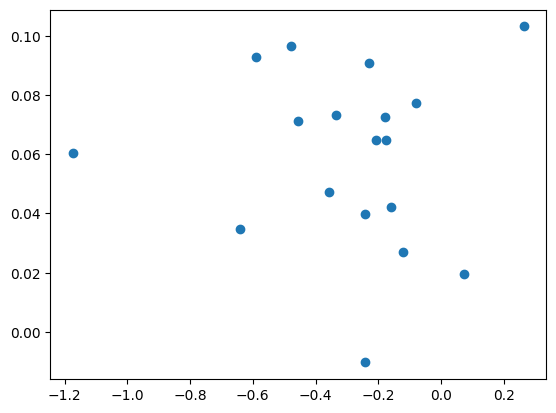

[[0.00011601 0.00018081]
 [0.00018081 0.00043255]]
Vietnam !!!
Vietnam ???


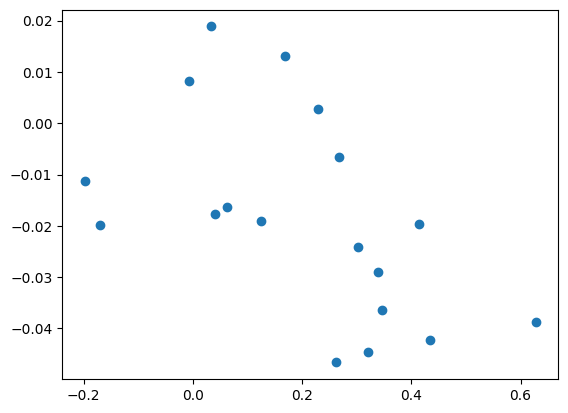

[[ 3.12817404e-05 -6.45537709e-05]
 [-6.45537709e-05  2.34115268e-04]]
Greece !!!
Greece ???


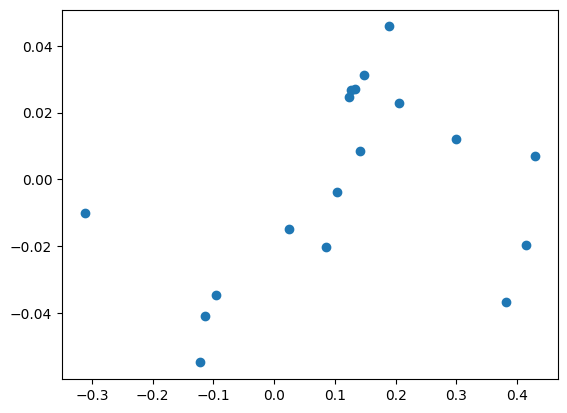

[[ 4.71978722e-05 -9.98305157e-05]
 [-9.98305157e-05  1.09044717e-03]]
Poland !!!
Poland ???


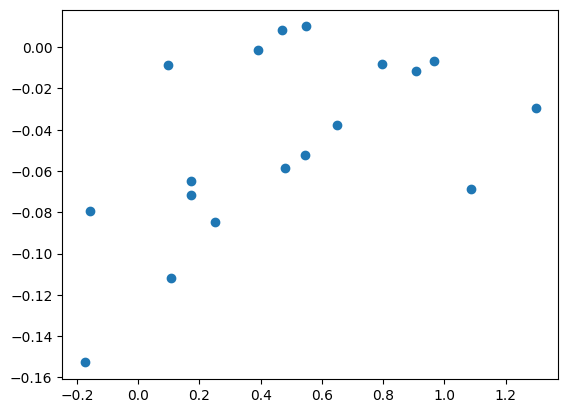

[[ 0.00024433 -0.00030858]
 [-0.00030858  0.00055036]]
Portugal !!!
Portugal ???


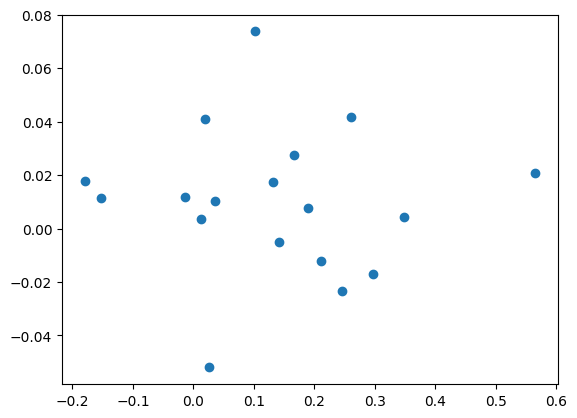

[[ 5.42201435e-05 -8.56373380e-05]
 [-8.56373380e-05  5.01867956e-04]]
France !!!
France ???


In [60]:
#in the report we reference the SOI for a country "as compared with its peers"

all_country_soi = compute_soi_adi(adi, country_list, product_list,country_list, product_list2, opportunity_gain)
sorted_soi = sorted(all_country_soi.items(), key=operator.itemgetter(1))
soi_rank = sorted_soi.index((main_country, all_country_soi[main_country])) + 1

In [61]:
sorted_soi

[('Vietnam', np.float64(-0.061454632966432055)),
 ('France', np.float64(-0.06079558950607944)),
 ('Poland', np.float64(0.05736941883169344)),
 ('Greece', np.float64(0.23499453620052935)),
 ('Portugal', np.float64(0.24052553399033927))]

In [62]:
#I made this run without crashing but its still wrong.

soi_pctl = soi_rank / len(sorted_soi)

if soi_pctl < 0.25:
  jsonout['[SOI quartile]'] = 'bottom'
  jsonout['[SOI quality]'] = 'low'
  for contrastcountry, contrastsoi in sorted_soi[-5:]:
    if (contrastgdp := aagrate([x[1] for x in gdp_range_dict[contrastcountry]])) > 0.3:
      jsonout['[SOI Contrast Country]'] = contrastcountry
      jsonout['[SOI Contrast Country Quality]'] = 'high'
      jsonout['[SOI Contrast]'] = contrastsoi
      jsonout['[SOI Contrast GDP]'] = contrastgdp
      jsonout['SOI Contrast GDP Quality'] = 'fastest'
      break

elif soi_pctl < 0.5:
  jsonout['[SOI quartile]'] = 'second'
  jsonout['[SOI quality]'] = 'moderate'
  for contrastcountry, contrastsoi in sorted_soi[-5:]:
    if (contrastgdp := aagrate([x[1] for x in gdp_range_dict[contrastcountry]])) > 0.3:
      jsonout['[SOI Contrast Country]'] = contrastcountry
      jsonout['[SOI Contrast Country Quality]'] = 'high'
      jsonout['[SOI Contrast]'] = contrastsoi
      jsonout['[SOI Contrast GDP]'] = contrastgdp
      jsonout['SOI Contrast GDP Quality'] = 'fastest'
      break

elif soi_pctl < 0.75:
  jsonout['[SOI quartile]'] = 'third'
  jsonout['[SOI quality]'] = 'moderate'

  for contrastcountry, contrastsoi in sorted_soi[:5]:
    if (contrastgdp := aagrate([x[1] for x in gdp_range_dict[contrastcountry]])) < 0.15:
      jsonout['[SOI Contrast Country]'] = contrastcountry
      jsonout['[SOI Contrast Country Quality]'] = 'low'
      jsonout['[SOI Contrast]'] = contrastsoi
      jsonout['[SOI Contrast GDP]'] = contrastgdp
      jsonout['SOI Contrast GDP Quality'] = 'slowest'
      break

else:
  jsonout['[SOI quartile]'] = 'top'
  jsonout['[SOI quality]'] = 'high'

  for contrastcountry, contrastsoi in sorted_soi[:5]:
    if (contrastgdp := aagrate([x[1] for x in gdp_range_dict[contrastcountry]])) < 0.15:
      jsonout['[SOI Contrast Country]'] = contrastcountry
      jsonout['[SOI Contrast Country Quality]'] = 'low'
      jsonout['[SOI Contrast]'] = contrastsoi
      jsonout['[SOI Contrast GDP]'] = contrastgdp
      jsonout['SOI Contrast GDP Quality'] = 'slowest'
      break

jsonout['[SOI]'] = all_country_soi[main_country]

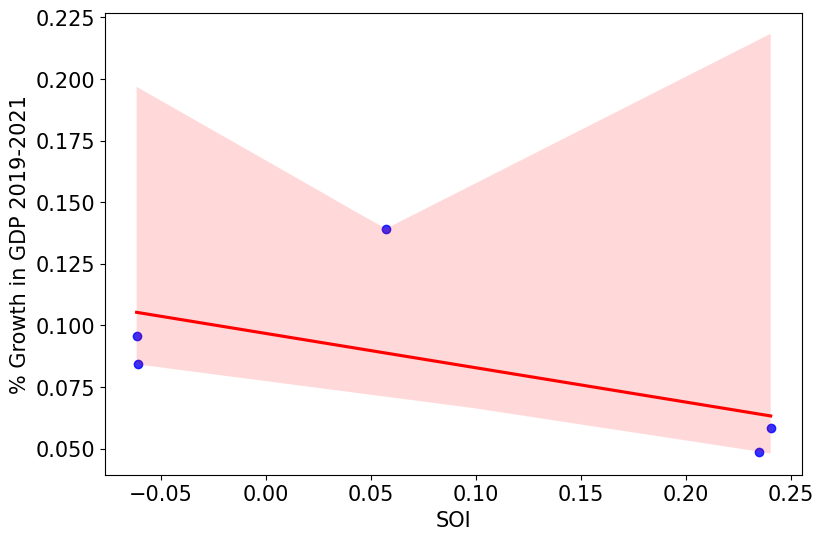

/usr/local/lib/python3.12/dist-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


'soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)\nsoi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))\n\n#UPDATED - GDP4 needed other reworks\n\ngdp_raw = gdp_df.fillna(0)\n\nreg, growth = compute_regress(soi_adi, gdp_raw, country_list, country_list2)\n\n# print(len(country_list))\n# print(len(country_list2))\n# print(len(soi_adi_list))\nreg.summary()'

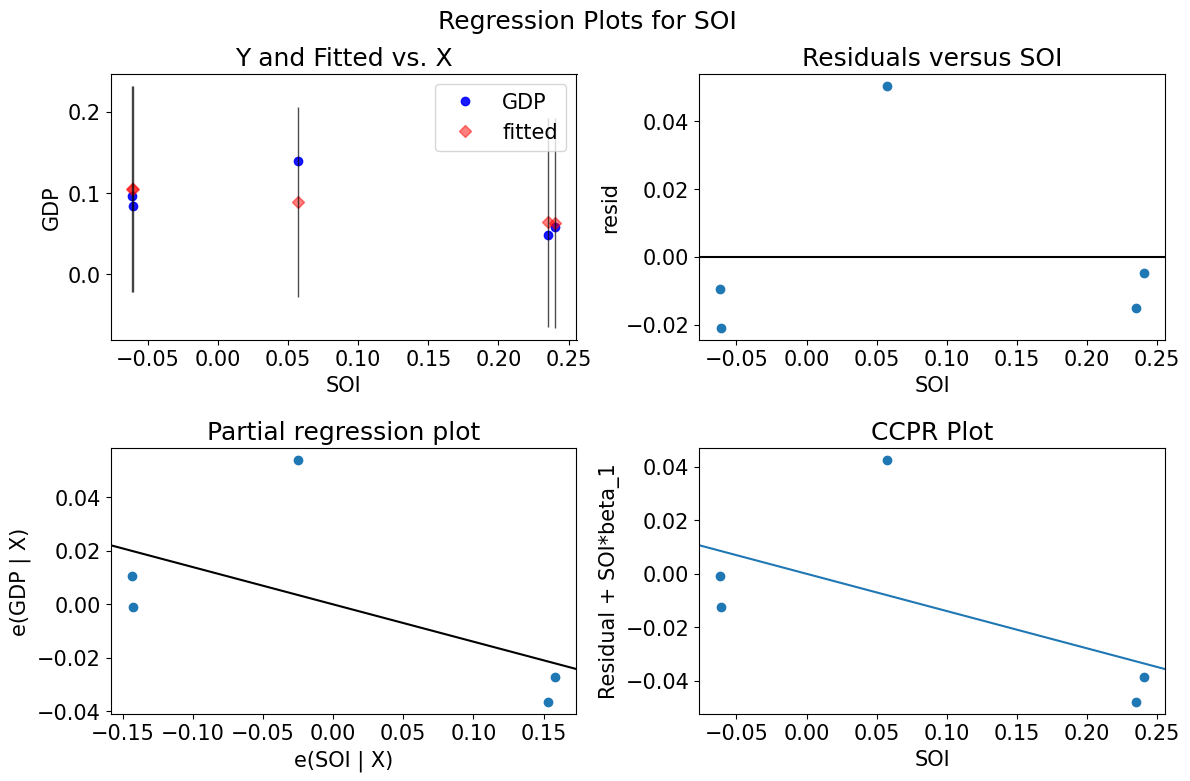

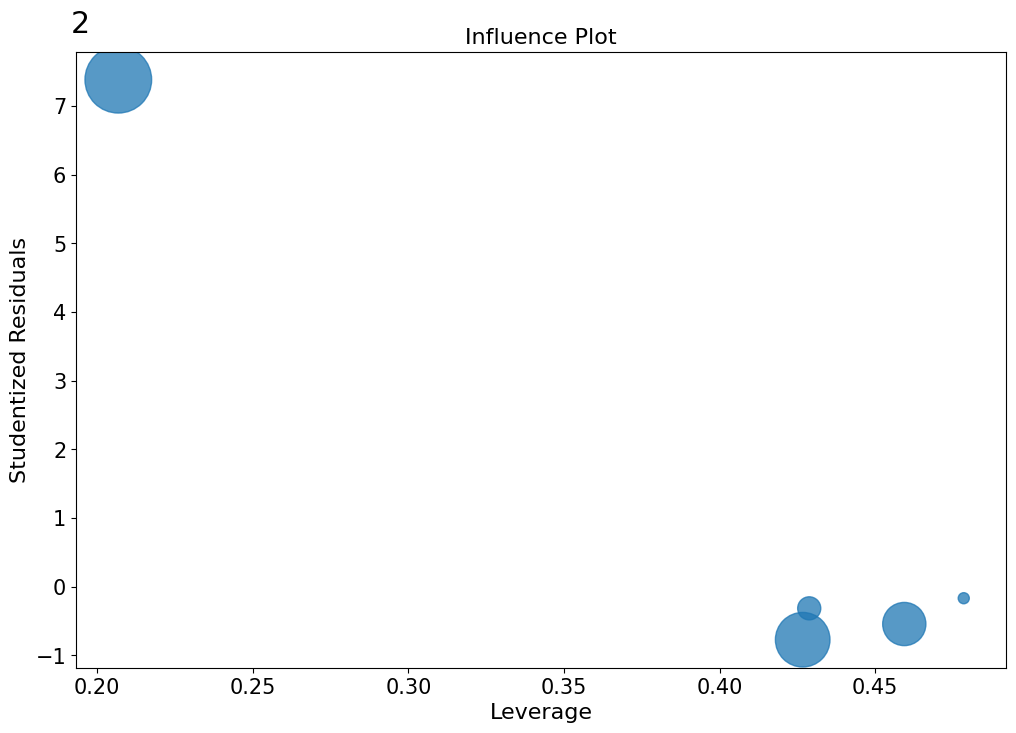

In [63]:


#gdp_raw=pd.read_csv(GDP4_path+'/GDP4.csv', index_col=0).fillna(0) #File path updated - JZ
gdp_raw=gdp_df.fillna(0)
gdp_raw.set_index('Country', inplace=True)
#pd.read_csv(path_to_data+'GDP_2022.csv', index_col=0).fillna(0) #NZ: Change to GDP_2022

reg, growth = compute_regress(all_country_soi, gdp_raw, country_list, country_list2)

jsonout['[R^2]'] = reg.rsquared
jsonout['[R^2 adj]'] = reg.rsquared_adj
jsonout['[F-Stat]'] = reg.fvalue
jsonout['[Prob]'] = reg.f_pvalue
jsonout['[nobs]'] = reg.nobs

reg.summary()

"""soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)
soi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))

#UPDATED - GDP4 needed other reworks

gdp_raw = gdp_df.fillna(0)

reg, growth = compute_regress(soi_adi, gdp_raw, country_list, country_list2)

# print(len(country_list))
# print(len(country_list2))
# print(len(soi_adi_list))
reg.summary()"""

In [65]:
jsonout

{'[Country]': 'Vietnam',
 '[Category]': 'developed',
 '[Start Year]': 2019,
 '[End Year]': 2023,
 '[GDP growth rate]': '5.59',
 '[GDP growth quality]': 'high',
 '[Relative GDP growth quality]': 'moderate',
 '[ECI growth quality]': 'increased',
 '[Y]': np.int64(17),
 '[X]': np.int64(1),
 '[Industry development]': 'progressed',
 '[increased/decreased]': 'decreased',
 '[SOI quartile]': 'bottom',
 '[SOI quality]': 'low',
 '[SOI Contrast Country]': 'Vietnam',
 '[SOI Contrast Country Quality]': 'high',
 '[SOI Contrast]': np.float64(-0.061454632966432055),
 '[SOI Contrast GDP]': 5.589653132544088,
 'SOI Contrast GDP Quality': 'fastest',
 '[SOI]': np.float64(-0.061454632966432055),
 '[R^2]': np.float64(0.3436971453744434),
 '[R^2 adj]': np.float64(0.12492952716592454),
 '[F-Stat]': np.float64(1.571060416477395),
 '[Prob]': np.float64(0.29884470761277193),
 '[nobs]': 5.0,
 '[Overall quality]': 'positive',
 '[Strategy quality]': 'improved'}

In [66]:
# IMPORTANT. RUN THIS TO SAVE JSON.

import json

if jsonout["[GDP growth quality]"] == "high" and jsonout["[ECI growth quality]"] == "increased":
  jsonout["[Overall quality]"] = "positive"
  jsonout["[Strategy quality]"] = "improved"
elif jsonout["[GDP growth quality]"] == "low" and jsonout["[ECI growth quality]"] == "decreased":
  jsonout["[Overall quality]"] = "negative"
  jsonout["[Strategy quality]"] = "declining"
else:
  jsonout["[Overall quality]"] = "mixed"
  jsonout["[Strategy quality]"] = "stagnant"


with open(jsonpath, 'w') as f:
    json.dump(jsonout, f, indent=4, default=lambda x: x.item() if hasattr(x, "item") else x)

In [69]:
!pip install -U "kaleido==0.2.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 MB 6.1 MB/s eta 0:00:00
  Attempting uninstall: kaleido
    Found existing installation: kaleido 1.2.0
    Uninstalling kaleido-1.2.0:
      Successfully uninstalled kaleido-1.2.0


In [70]:
c= main_country
soi_plotter(c, adi, country_list, product_list, country_list2, product_list2, opportunity_gain)
print('SOI', all_country_soi[c],'Growth', growth[c])

categorization verified


ValueError: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido


SOI w/ Opportunity Gain

In [ ]:
#52
soi_oppg= compute_soi_oppgain(country_list, product_list,country_list_last_year, product_list_last_year, opportunity_gain, opportunity_gain_18)
print(sorted(soi_oppg.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_last_year))
reg_opp= compute_regress(soi_oppg, gdp_raw, country_list, country_list_last_year) #updated "Country Name" key to "Country" - JZ
print(reg_opp[0].summary())

#reg_opp.summary()

In [ ]:
gdp_raw

# End of Comprenesive

In [ ]:
assert(False)

# 2. Greedy Budget Allocation

This code file takes in a country's economic data and runs a greedy algorithm to maximize its ECI for each budget percentage (5%, 10%, 15%, 20%). Then, the output with all the path increments is saved into a pickle file
#### TO DO:

In [ ]:
#53
#TO DO: make sure to create a folder New_result_update in your OWN drive
path = 'newdrive/My Drive/New_result_update/'

#updated
#root_path = 'drive/My Drive/ECI Research/Fall 2022/Data/2019-2021 cleaned/'
#NZ: Root path updated to reflect 2022:
root_path = 'newdrive/My Drive/ECI Research/5. Datasets/'+folder+'/' + data_folder +"/"


# TO DO: UPDATE to the main country
# main_country = 'Colombia'

In [ ]:
#54
#### Import packages
#Install xlwt:
"""!pip install xlwt
Install the kaleido package for exporting images
!pip install -U kaleido"""

#needed to downgrade plotly for kaleido to work; the code seems to run fine with the lower version,
#but let me know if we run into issues
!pip install plotly==5.3.1
import io
import os
import csv
import statsmodels.api as sm
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import operator
import xlwt
import tqdm
import sys, os
import multiprocessing
import plotly.graph_objects as go
import plotly.graph_objects as go
import pickle

from plotly.offline import plot
from plotly.subplots import make_subplots
from xlwt import Workbook
from functools import partial
from scipy import linalg as LA
import copy
from functools import partial
import plotly.graph_objects as go
from plotly.subplots import make_subplots


### Metrics calculation

#### MCP

In [ ]:
#55
# MCP:

def compute_mcp(matrix):
  product_list = matrix[0][1::]
  country_list = []
  for i in range(1,len(matrix)):
    country_list.append(matrix[i][0])

  country_sum = []
  for i in range(1,len(matrix)):
    country_sum.append(np.sum(matrix[i][1::]))

  product_sum = []
  for i in range(1,len(matrix[0])):
    product = 0
    for j in range(1,len(matrix)):
        product += matrix[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcp = []

  for i in range (1,len(matrix)):
    country_row = []
    for j in range(1,len(matrix[i])):
      try:
        percentage = matrix[i][j]/country_sum[i-1]
      except:
        print(country_list[i-1])
      total_percentage = product_sum[j-1]/total_sum
      if percentage > total_percentage:
        country_row.append(1)
      else:
        country_row.append(0)
    mcp.append(country_row)

  return country_list, product_list, mcp, product_sum, country_sum

#### MCC

In [ ]:
#56
# MCC:

def compute_mcc(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcc = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp)):
      temp_sum = 0
      for k in range(0,len(mcp[0])):
        try:
          value = (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
          if np.isinf(value) or np.isnan(value):
            temp_sum += 0
          else:
            temp_sum += value
        except:
          pass
      country_row.append(temp_sum)
    mcc.append(country_row)
  return mcc

#### MPP

In [ ]:
#57
#MPP:

def compute_mpp(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mpp = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += (mcp[k][i] * mcp2[k][j]/(country_sum[k]*product_sum[i]))
        except:
          pass
      product_row.append(temp_sum)
    mpp.append(product_row)
  return mpp

#### ECI

In [ ]:
#58
#### ECI
def compute_eci(mcc):
  mcc = np.array(mcc)

  e_vals, e_vecs = LA.eig(mcc)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  eci = []
  if vector[0] < 0:
    for item in vector:
      eci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      eci.append((-item+np.mean(vector))/np.std(vector))
  return eci

#### PCI

In [ ]:
#59
# PCI:

def compute_pci(mpp):
  mpp = np.array(mpp)
  e_vals, e_vecs = LA.eig(mpp)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  pci = []
  if vector[len(vector)-2] > 0:
    for item in vector:
      pci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      pci.append((-item+np.mean(vector))/np.std(vector))
  return pci

#### Proximity

In [ ]:
#60
#### Proximity
def compute_proximity(mcp, product_sum):
  proximity = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += mcp[k][i] * mcp[k][j]
        except:
          pass
      p0 = product_sum[i]
      p1 = product_sum[j]
      if p0 < p1:
        large = p1
      else:
        large = p0
      product_row.append(temp_sum/large)
    proximity.append(product_row)
  return proximity

#### Distance

In [ ]:
#61
#Distance:

def compute_distance(mcp, proximity):
  distance = []
  for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
      sum1 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum1 += mcp[i][k]*proximity[j][k]
          except:
            pass
      sum2 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum2 += proximity[j][k]
          except:
            pass
      product_row.append(1-sum1/sum2)
    distance.append(product_row)
  return distance

#### Opportunity Gain

In [ ]:
#62
#Opportunity Gain:


def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        country_row.append(gain)
      #country_row.append(gain)
    opportunity_gain.append(country_row)

  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain


#### Marginal Oppotunity Gain

In [ ]:
63
#### marginal oppotunity gain
def compute_marginal_opportunity_gain(mcp, opportunity_gain, country_sum,
                                      product_sum, raw_matrix):
  marginal = []
  total_sum = np.sum(product_sum)
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        export = raw_matrix[i+1][j+1]
        country_export = country_sum[i]
        product_export = product_sum[j]
        export_increase = (product_export * country_export / total_sum) - export
        country_row.append(opportunity_gain[i][j] * export / export_increase)
    marginal.append(country_row)

  marginal = np.array(marginal)
  return marginal

### Greedy

In [ ]:
#64
def two_step_greedy(country, year, num_part, percentage):

    df = pd.read_csv(path_to_data+data_folder+"/" + f'{year}clean.csv')

    raw_matrix = df.to_numpy() # export data with only values

    matrix = [list(df.columns)] # export data with IDs and values

    for row in raw_matrix:
      matrix.append(list(row))

    product_list = matrix[0][1::]
    country_list = []

    for i in range(1,len(matrix)):         # Search country index
        country_list.append(matrix[i][0])

        if country == 'USA' or country == 'France':
            if country in matrix[i][0]:
                country_index = i
                total_export = np.sum(matrix[i][1::])
                print(f'\nCountry: {country}, index is {i}')
        elif country == matrix[i][0]:
            country_index = i
            total_export = np.sum(matrix[i][1::])
            print(f'\nCountry: {country}, index is {i}')

    budget = (percentage/100) * total_export
    share = budget/num_part
    weapon_index = matrix[0].index('Weapons')
    weapon_value = matrix[country_index][weapon_index]

    print(f'Original total export is {total_export}, budget is {budget}, share is {share}, percentage is {budget/total_export*100}%.')
    mcp, product_sum, country_sum = compute_mcp(matrix)[2:]
    mcc = compute_mcc(mcp)
    eci = compute_eci(mcc)
    mpp = compute_mpp(mcp)
    pci = compute_pci(mpp)
    distances = compute_proximity(mcp, product_sum)

    last_eci = eci[country_index-1]
    print(f'ECI this year is {last_eci}')
    original_vector = np.copy(matrix[country_index][1::])

    total = 0
    improvement_index = []
    improvement_percentage = [0]
    eci_increment = [last_eci]
    improved_matrix = copy.deepcopy(matrix)

    while total + 200 < budget:

        print(f'\nProgress: {round(total/budget, 2)}')

        multiplier = 0

        stop_1 = 0
        stop_2 = 0
        budget_reach = 0

        achieved_eci_1 = 0
        achieved_eci_2 = 0

        total_budget_1 = 0
        total_budget_2 = 0

        last_budget = 0

        while stop_1 == 0 or stop_2 == 0:

            if total + share * multiplier + 200 >= budget:

                budget_reach = 1

            else:

                multiplier += 1

            print(f'Path 1: {stop_1}, Path 2: {stop_2}, multiplier: {multiplier}, keep increasing multiplier.')

            eci_temp = []

            matrix_ = copy.deepcopy(improved_matrix)
            for i in range(1, len(matrix[0])):  # make changes on the matrix with data and IDs, index has to start from 1

                matrix_[country_index][i] += share * multiplier
                country_list, product_list, mcp, product_sum, country_sum = compute_mcp(matrix_)
                mcc = compute_mcc(mcp)

                if i == weapon_index:

                    ratio = (matrix_[country_index][weapon_index] - weapon_value)/weapon_value

                    if ratio > 0.1:

                        eci_temp.append((-1)*np.inf)  # The limit of the increment of weapon is 10%
                    else:

                        eci_temp.append(compute_eci(mcc)[country_index - 1])  # index minus 1 because of the matrix without IDs
                else:

                    eci_temp.append(compute_eci(mcc)[country_index - 1])

                matrix_[country_index][i] -= share * multiplier

            if ((max(eci_temp) > last_eci and total + share * multiplier > last_budget)
                or budget_reach) and stop_1 == 0: # Check whether the eci in path 1 has improved

                stop_1 = 1

                if max(eci_temp) > last_eci:

                    print('Path 1 find increments. Stop path 1.')
                    if eci_temp.count(max(eci_temp)) > 1:

                        indices = np.where(np.array(eci_temp) == np.max(eci_temp))[0]
                        max_pci = np.max(np.array(pci)[indices])
                        index_1 = np.where(np.array(pci) == max_pci)[0][0]

                    elif eci_temp.count(max(eci_temp)) == 1:

                        index_1 = np.argmax(eci_temp)

                elif budget_reach:

                    print(f'Total reached {total + share * multiplier}. Path 1 to the end.')
                    mcp, product_sum, country_sum = compute_mcp(improved_matrix)[2:]
                    proximity = compute_proximity(mcp, product_sum)
                    all_distances = compute_distance(mcp, proximity)
                    distances = all_distances[country_index - 1]
                    index_1 = list(distances).index(min(np.array(distances)[np.array(distances)>0]))
                    compute_distance(mcp, proximity)

                achieved_eci_1 = max(eci_temp)
                total_budget_1 = total + share * multiplier
                last_budget = total_budget_1

            if ((max(eci_temp) > achieved_eci_1 and stop_1 == 1)
                or budget_reach) and stop_2 == 0: # Check whether the eci in path 2 has improved

                stop_2 = 1

                if max(eci_temp) > last_eci:

                    print('Path 2 find increments. Stop path 2.')
                    if eci_temp.count(max(eci_temp)) > 1:

                        indices = np.where(np.array(eci_temp) == np.max(eci_temp))[0]
                        max_pci = np.max(np.array(pci)[indices])
                        index_2 = np.where(np.array(pci) == max_pci)[0][0]

                    elif eci_temp.count(max(eci_temp)) == 1:

                        index_2 = np.argmax(eci_temp)

                elif budget_reach:

                    print(f'Total reached {total + share * multiplier}. Path 2 to the end.')
                    mcp, product_sum, country_sum = compute_mcp(improved_matrix)[2:]
                    proximity = compute_proximity(mcp, product_sum)
                    all_distances = compute_distance(mcp, proximity)
                    distances = all_distances[country_index - 1]
                    index_2 = list(distances).index(min(np.array(distances)[np.array(distances)>0]))

                achieved_eci_2 = max(eci_temp)
                total_budget_2 = total + share * multiplier

        print(f'path 1 differnce:{total_budget_1 - total}')
        print(f'path 2 differnce:{total_budget_2 - total}')
        ratio_1 = (achieved_eci_1 - last_eci)/(total_budget_1 - total)
        ratio_2 = (achieved_eci_2 - last_eci)/(total_budget_2 - total)

        if ratio_1 < ratio_2:

            total = total_budget_2
            print(f'Select path 2, total right now is {total}')
            print(f'Path 2 largest argument is {index_2 + 1}, product is {product_list[index_2]}')
            if achieved_eci_2 > last_eci:

              print(f'last ci is {last_eci}, this eci is {achieved_eci_2}')
              last_eci = achieved_eci_2

            else:
              print(f'last ci is {last_eci}, this eci is {last_eci}')

            improved_matrix[country_index][index_2 + 1] += total_budget_2
            improvement_percentage.append(total_budget_2/budget)
            improvement_index.append(index_2 + 1)

        else:

            total = total_budget_1
            print(f'Select path 1, total right now is {total}')
            print(f'Path 1 largest argument is {index_1 + 1}, product is {product_list[index_1]}')

            if achieved_eci_1 > last_eci:

              print(f'last ci is {last_eci}, this eci is {achieved_eci_1}')
              last_eci = achieved_eci_1

            else:
              print(f'last ci is {last_eci}, this eci is {last_eci}')

            improved_matrix[country_index][index_1 + 1] += total_budget_1
            improvement_percentage.append(total_budget_1/budget)
            improvement_index.append(index_1 + 1)

        eci_increment.append(last_eci)

    optimal_allocation = np.round(np.array(improved_matrix[country_index][1::])\
                                  - original_vector, 2)
    max_eci = last_eci

    return dict(zip(product_list,optimal_allocation)), improvement_percentage, \
            eci_increment, total_export, improvement_index


In [ ]:
#65
# TO FIX

#This function doesn't seem to be called anywhere; I'm not sure what the use is
def greedy_stablizer(country, year, percentage, num_part):
    num_part = np.linspace(5, 30, num=6)
    result = []
    for part in num_part:
      result.append(two_step_greedy(country, year, percentage, part))
    eci = [i[1] for i in result]
    m = max(eci)
    max_index = [i for i, j in enumerate(eci) if j == m]
    optimal_index = 0
    diversity = sum(1 for i in result[max_index[0]][0].values() if i >= 0)
    for index in max_index:
      if sum(1 for i in result[max_index[index]][0].values() if i >= 0) > diversity:
        optimal_index = index
    return result[optimal_index]

### Plot

In [ ]:
def pie_plot(country, allocations):
    labels = []
    for i in range(len(allocations)):
        allocations[i] = {x:y for x,y in allocations[i].items() if y!=0}
        labels.append(list(allocations[i].keys()))
    specs = [[{'type':'domain'}, {'type':'domain'}, {'type':'domain'}, {'type':'domain'}]]
    fig = make_subplots(rows=1, cols=4, specs = specs)
    fig.add_trace(go.Pie(labels=labels[0], values=np.asarray(list(allocations[0].values()))/np.sum(list(allocations[0].values())),
                         name="5% growth"), 1, 1)
    fig.add_trace(go.Pie(labels=labels[1], values=np.asarray(list(allocations[1].values()))/np.sum(list(allocations[1].values())),
                         name="10% growth"), 1, 2)
    fig.add_trace(go.Pie(labels=labels[2], values=np.asarray(list(allocations[2].values()))/np.sum(list(allocations[2].values())),
                         name="15% growth"), 1, 3)
    fig.add_trace(go.Pie(labels=labels[3], values=np.asarray(list(allocations[3].values()))/np.sum(list(allocations[3].values())),
                         name="20% growth"), 1, 4)

    # Use `hole` to create a donut-like pie chart
    fig.update_traces(hole=.4, hoverinfo="label+percent+name")

    fig.update_layout(
        title_text=f"{country} ECI Growth Optimization Result",
        # Add annotations in the center of the donut pies.
        font=dict(
        family="Times New Roman"),
        annotations=[dict(text='5', x=0.095, y=0.5, font_size=20, showarrow=False),
                     dict(text='10', x=0.37, y=0.5, font_size=20, showarrow=False),
                     dict(text='15', x=0.63, y=0.5, font_size=20, showarrow=False),
                     dict(text='20', x=0.91, y=0.5, font_size=20, showarrow=False)])
    #fig.update_layout(margin=dict(t=50, b=0, l=0, r=0))
    fig.write_image('/content/drive/My Drive/ECI Auto Report Test/img/kix.qkzmpvrz2v9z.png', engine="kaleido")
    fig.show()

def eic_growth_plot(country, eci_increment):
    trace1 = go.Scatter(x = list(range(0, len(eci_increment[0]))),
                         y = eci_increment[0], name="5% growth",
                        line=dict(width=6),marker=dict(size=15))

    trace2 = go.Scatter(x = list(range(0, len(eci_increment[1]))), xaxis="x2",
                         y = eci_increment[1], name="10% growth",
                        line=dict(width=6), marker=dict(size=15))

    trace3 = go.Scatter(x = list(range(0, len(eci_increment[2]))), xaxis="x3",
                         y = eci_increment[2], name="15% growth",
                        line=dict(width=6), marker=dict(size=15))

    trace4 = go.Scatter(x = list(range(0, len(eci_increment[3]))), xaxis="x4",
                         y = eci_increment[3], name="20% growth",
                        line=dict(width=6), marker=dict(size=15))

    data = [trace1, trace2, trace3, trace4]

    layout = go.Layout(
        xaxis=dict(
            domain=[0, 0.25]
        ),
        legend=dict(
            traceorder="reversed"
        ),
        xaxis2=dict(
            domain=[0.25, 0.5]
        ),
        xaxis3=dict(
            domain=[0.5, 0.75]
        ),
        xaxis4=dict(
            domain=[0.75, 1]
        ),
        title_text=f"{country} ECI Growth",
        font=dict(
        family="Times New Roman")

    )
    fig = go.Figure(data=data, layout=layout)
    fig.update_layout(height=400, width=900, title_text=f"{country} ECI Increment", showlegend=True)
    fig.write_image('/content/drive/My Drive/ECI Auto Report Test/img/kix.u68suuv7ge1c.png', engine="kaleido")
    fig.show()

### Running Greedy:

In [ ]:
# TO FIX: add "loud" so htat we don't print but also make for loops into a funciton

In [ ]:
#67
#Running Greedy Below:
# 5%
# This algo runs for a while (~25min)
country = main_country
year = 2022 #Updated year
num_share = [30, 60, 90, 120]
budget_percentage = [5] # Run for percentages of: [5,10,15,20]

all_result = []
all_allocations = []
all_eci_increments = []
#Running two-step greedy:

for iter, budget in enumerate(budget_percentage):

    result = two_step_greedy(country, year, num_share[iter], budget)
    allocation = result[0]
    eci_increment = result[2]

    all_result.append(result)
    all_allocations.append(allocation)
    all_eci_increments.append(eci_increment)

for j in range(1):
    with open(path + f'{country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p', 'wb') as fp:
          pickle.dump(all_result[j], fp, protocol=pickle.HIGHEST_PROTOCOL)

In [ ]:
#69
# 10%
# This algo runs for a while (~25min)
country = main_country
year = 2022 #Updated year
num_share = [30, 60, 90, 120]
budget_percentage = [10] # Run for percentages of: [5,10,15,20]

all_result = []
all_allocations = []
all_eci_increments = []

#Running two-step greedy:

for iter, budget in enumerate(budget_percentage):

    result = two_step_greedy(country, year, num_share[iter], budget)
    allocation = result[0]
    eci_increment = result[2]

    all_result.append(result)
    all_allocations.append(allocation)
    all_eci_increments.append(eci_increment)

for j in range(1):
    with open(path + f'{country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p', 'wb') as fp:
          pickle.dump(all_result[j], fp, protocol=pickle.HIGHEST_PROTOCOL)

In [ ]:
#70
# 15%
# This algo runs for a while (~20min)
country = main_country
year = 2022 #Updated year
num_share = [30, 60, 90, 120]
budget_percentage = [15] # Run for percentages of: [5,10,15,20]

all_result = []
all_allocations = []
all_eci_increments = []

#Running two-step greedy:

for iter, budget in enumerate(budget_percentage):

    result = two_step_greedy(country, year, num_share[iter], budget)
    allocation = result[0]
    eci_increment = result[2]

    all_result.append(result)
    all_allocations.append(allocation)
    all_eci_increments.append(eci_increment)

for j in range(1):
    with open(path + f'{country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p', 'wb') as fp:
          pickle.dump(all_result[j], fp, protocol=pickle.HIGHEST_PROTOCOL)

In [ ]:
#71
# 20%
# This algo runs for a while (~15min)
country = main_country
year = 2022 #Updated year
num_share = [30, 60, 90, 120]
budget_percentage = [20] # Run for percentages of: [5,10,15,20]

all_result = []
all_allocations = []
all_eci_increments = []

#Running two-step greedy:

for iter, budget in enumerate(budget_percentage):

    result = two_step_greedy(country, year, num_share[iter], budget)
    allocation = result[0]
    eci_increment = result[2]

    all_result.append(result)
    all_allocations.append(allocation)
    all_eci_increments.append(eci_increment)

for j in range(1):
    with open(path + f'{country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p', 'wb') as fp:
          pickle.dump(all_result[j], fp, protocol=pickle.HIGHEST_PROTOCOL)
#all_eci_increments

# 3. Plot Budget Allocation

#### Code Description:

- This code processes allocation data to calculate the optimal allocation of products for different growth rates.
- It generates pie charts to visualize the allocations and graphs to show the country's ECI growth over time for each growth rate.
- Additionally, it creates an Excel file that provides allocation data for the country.

#### TO DO:

In [71]:
#72


# TO FIX - PORTFOLIO TABLE EXPORT (take from MD old 3 https://colab.research.google.com/drive/1xq_vhnvKl4fIz0I-LflZXWYPD5gsymo3?usp=sharing)

# TO DO Modify country here
country =  main_country#'Senegal'

folder = "2024 Fall - Data/"
data_folder = "2019-2023 cleaned"
root_path = 'drive/My Drive/ECI Research/2024 Fall - Data/2019-2023 cleaned/'

path = 'drive/My Drive/New_result_update/'
# After all code is ran, click on the menu on the folder icon to side on the left
# download "tableau [country] 2021.xls"
# will give a portfolio for the country

# "Italy ECI Growth Optimization Result.png" and "Italy ECI Increment.png" are the graphs produced

#### Import packages

In [72]:


  #Install xlwt
#!pip install xlwt
  #Install the kaleido package for exporting images
#!pip install -U kaleido

#needed to downgrade plotly for kaleido to work; the code seems to run fine with the lower version,
#but let me know if we run into issues
!pip install plotly==5.3.1
import io
import os
import csv
import statsmodels.api as sm
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import operator
import xlwt
import tqdm
import sys, os
import multiprocessing
import plotly.graph_objects as go
import plotly.graph_objects as go
import pickle

from plotly.offline import plot
from plotly.subplots import make_subplots
from xlwt import Workbook
from functools import partial
from scipy import linalg as LA
import copy
from functools import partial
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pickle

In [73]:
product_list = ['Animals and By-products',
                'Vegetables, Fruits and Plants',
                'Food and Preparations',
                'Energy Drilling and Mining',
                'Chemicals',
                'Chemical Manufacturing',
                'Raw Manufacturing',
                'Wood Products',
                'Clothing and Accessories',
                'Textile',
                'Metals',
                'Machinery and Construction',
                'Transportation',
                'Weapons',
                'Daily Instruments',
                'Precious Stones',
                'High-complexity Products',
                'Services and Utilities']
num_to_products = {1: 'Animals and By-products',
                   2: 'Vegetables, Fruits and Plants',
                   3: 'Food and Preparations',
                   4: 'Energy Drilling and Mining',
                   5: 'Chemicals',
                   6: 'Chemical Manufacturing',
                   7: 'Raw Manufacturing',
                   8: 'Wood Products',
                   9: 'Clothing and Accessories',
                   10: 'Textile',
                   11: 'Metals',
                   12: 'Machinery and Construction',
                   13: 'Transportation',
                   14: 'Weapons',
                   15: 'Daily Instruments',
                   16: 'Precious Stones',
                   17: 'High-complexity Products',
                   18: 'Services and Utilities'}

#### Util

In [74]:

def cal_allocation(allocations, percentages, indices, num_to_products):

    all_total = []
    all_allocation_percentage_dict = []
    all_allocation_dict = []

    for i in range(4):
        all_total.append(np.max(list(allocations[i].values())))



    for i in range(4):

        allocation_percentage_dict = {}

        for iter, index in enumerate(indices[i]):
            if index in list(allocation_percentage_dict.keys()):
              allocation_percentage_dict[index] += percentages[i][iter+1] -\
                                                            percentages[i][iter]
            else:
              allocation_percentage_dict[index] = percentages[i][iter+1] -\
                                                            percentages[i][iter]
        all_allocation_percentage_dict.append(allocation_percentage_dict)

    for i in range(4):

        allocation_dict = {}
        for key, value in all_allocation_percentage_dict[i].items():

            allocation_dict[num_to_products[key]] = value * all_total[i]

        all_allocation_dict.append(allocation_dict)

    return all_allocation_dict

#### Pie plots

In [75]:
#### Pie plots
def pie_plot(country, allocations):

    labels = []
    for i in range(len(allocations)):
        allocations[i] = {x:y for x,y in allocations[i].items() if y!=0}
        labels.append(list(allocations[i].keys()))
    specs = [[{'type':'domain'}, {'type':'domain'}, {'type':'domain'}, {'type':'domain'}]]
    fig = make_subplots(rows=1, cols=4, specs = specs)
    fig.add_trace(go.Pie(labels=labels[0], values=np.asarray(list(allocations[0].values()))/np.max(list(allocations[0].values())),
                         name="5% growth"), 1, 1)
    fig.add_trace(go.Pie(labels=labels[1], values=np.asarray(list(allocations[1].values()))/np.max(list(allocations[1].values())),
                         name="10% growth"), 1, 2)
    fig.add_trace(go.Pie(labels=labels[2], values=np.asarray(list(allocations[2].values()))/np.max(list(allocations[2].values())),
                         name="15% growth"), 1, 3)
    fig.add_trace(go.Pie(labels=labels[3], values=np.asarray(list(allocations[3].values()))/np.max(list(allocations[3].values())),
                         name="20% growth"), 1, 4)

    # Use `hole` to create a donut-like pie chart
    fig.update_traces(hole=.4, hoverinfo="label+percent+name")

    fig.update_layout(
        title_text=f"{country} ECI Growth Optimization Result",
        # Add annotations in the center of the donut pies.
        font=dict(
        family="Times New Roman"),
        annotations=[dict(text='5', x=0.095, y=0.5, font_size=20, showarrow=False),
                     dict(text='10', x=0.37, y=0.5, font_size=20, showarrow=False),
                     dict(text='15', x=0.63, y=0.5, font_size=20, showarrow=False),
                     dict(text='20', x=0.91, y=0.5, font_size=20, showarrow=False)],
        width=1000, height=500)
    #fig.update_layout(margin=dict(t=50, b=0, l=0, r=0))

    fig.show()

    # Save the plot as a PNG image
    fig.write_image(str(country) + " ECI Growth Optimization Result" + ".png", engine="kaleido")


In [76]:
#Plot for ECI vs time for different growth rates
import plotly.graph_objects as go

def eic_growth_plot(country, percentages, eci_increment, indices):

    data = []
    for i in range(len(percentages)):
        trace = go.Scatter(x=percentages[i],
                           y=eci_increment[i],
                           name=f"{(i+1)*5}% growth",
                           line=dict(width=2),
                           marker=dict(size=6))
        data.append(trace)

    layout = go.Layout(
        xaxis=dict(title="Percentages"),
        title_text=f"{country} ECI Growth",
        font=dict(family="Times New Roman"),
        legend=dict(
            traceorder="reversed"
        ),
    )

    fig = go.Figure(data=data, layout=layout)

    fig.update_layout(width=930, height=350,
                      yaxis_title="ECI",
                      title_text=f"{country} ECI Increment",
                      showlegend=True)

    fig.show()

    # Save the plot as a PNG image
    fig.write_image(str(country) + " ECI Increment" + ".png", engine="kaleido")

In [77]:

#BELOW: Old code that plotted the ECI increments along separate x-axes for the different growth rates

In [80]:
#to do - TO FIX - to check

year = 2022
num_share = [30 * i for i in range(1,5)]
budget_percentage = [5, 10, 15,20]

allocation = []

os.makedirs(path, exist_ok=True)
for j in range(4):
    with open(path+ f'{main_country}_{year}_percentage{budget_percentage[j]}_part{num_share[j]}.p', 'rb') as fp:
          allocation.append(pickle.load(fp))


allocations = [i[0] for i in allocation]
all_percentages = [i[1] for i in allocation]
all_eci_increments = [i[2] for i in allocation]
all_indices = [i[4] for i in allocation]

all_allocations = cal_allocation(allocations, all_percentages, all_indices,
                                 num_to_products)

pie_plot(main_country, all_allocations)
eic_growth_plot(main_country, all_percentages, all_eci_increments, all_indices)

FileNotFoundError: [Errno 2] No such file or directory: 'drive/My Drive/New_result_update/Vietnam_2022_percentage5_part30.p'

In [ ]:
# TO FIX this new code:

In [ ]:
#NZ: Define parameters:
year = 2022
budgets = ['5%', '10%', '15%', '20%']

In [ ]:
import dataframe_image as dfi

def write_tableu(country, year, all_allocations, all_eci_increments, budgets, product_list):

    all_products = []

    for i in range(4):

      all_products.extend(list(all_allocations[i].keys()))

    all_products = set(all_products)

    max_allocs = {}
    for p in all_products:
      max_allocs[p] = max([all_allocations[i].get(p, 0) for i in range(4)])

    max_allocs = sorted(max_allocs.items(), key=lambda x: x[1], reverse=True)

    jsonout['[Industry 1]'] = max_allocs[0]
    jsonout['[Industry 2]'] = max_allocs[1]
    jsonout['[Industry 3]'] = max_allocs[2]


    tableau_products = []

    for product in product_list:
        if product in all_products:
            tableau_products.append(product)


    df = pd.DataFrame()
    df['labels'] = ['Heuristic Export Growth'] + tableau_products + ['Increased ECI']
    for i in range(4):
      col = [f"{(i+1)*5}%"]
      for product in tableau_products:
        col.append(all_allocations[i].get(product, 0))
      col.append(all_eci_increments[i][-1])
      df[f"{(i+1)*5}%"] = col
    df = df.style.apply(lambda x: ['background-color: #bdd6ef' if i % 2 == 1 else 'background-color: #dfe9f9' for i in range(len(x))], axis = 0) \
            .apply(lambda x : ['background-color: darkblue' if i == 0 else "" for i in range(len(x))], axis = 0) \
            .apply(lambda x : ['color: white' if i == 0 else "color: black" for i in range(len(x))], axis = 0) \
            .set_table_styles([{'selector': 'thead', 'props': [('display', 'none')]}]) \
            .hide(axis='index')


    dfi.export(df, f'{AUTO_REPORT_PATH}/img/kix.lg1dve7hm257.png', table_conversion='matplotlib')

    col_num=0
    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    st = xlwt.easyxf('pattern: pattern solid;')
    st.pattern.pattern_fore_colour = 1
    sheet1.write(0, col_num, 'Heuristic Export Growth', st)

    for i in range(0,len(tableau_products)):

          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = 1
          sheet1.write(i+1, col_num, tableau_products[i], st)

    st = xlwt.easyxf('pattern: pattern solid;')
    st.pattern.pattern_fore_colour = 1
    sheet1.write(len(tableau_products)+1, col_num, 'Increased ECI', st)

    for iter, budget in enumerate(budgets):

        col_num += 1
        sheet1.write(0, col_num, budget, st)
        for j, product in enumerate(tableau_products):
            try:

              st = xlwt.easyxf('pattern: pattern solid;')
              st.pattern.pattern_fore_colour = 1
              sheet1.write(j+1, col_num, all_allocations[iter][product], st)
            except:

              st = xlwt.easyxf('pattern: pattern solid;')
              st.pattern.pattern_fore_colour = 1
              sheet1.write(j+1, col_num, 0, st)

        st = xlwt.easyxf('pattern: pattern solid;')
        st.pattern.pattern_fore_colour = 1
        sheet1.write(j+2, col_num, all_eci_increments[iter][-1], st)

    print(f'{country} {year} completed')
    book.save(f'tableau {country} {year}.xls')

    return

In [ ]:
allocations = [i[0] for i in allocation]
all_percentages = [i[1] for i in allocation]
all_eci_increments = [i[2] for i in allocation]
all_indices = [i[4] for i in allocation]

all_allocations = cal_allocation(allocations, all_percentages, all_indices,
                                 num_to_products)

In [ ]:
# TO FIX - this was ok before :
# TO DO:
write_tableu(main_country, year, all_allocations, all_eci_increments, budgets, product_list)

#click on folder icon to side on the left after running this and download .xls
# will give a portfolio for the country

# 4. Sensitivity

### Code Description:

- After all code is ran, click on the menu on the folder icon to side on the left to download
  - ECI vs "[country] (Positive) Shocking.png" and
  - ECI vs "[country] (Negative) Shocking.png" for relevant countries
- This code converts a country's economic data into a raw matrix and uses the matrix to compute the ECI value for each shock multiplier. The ECI with respect to each shock multiplier is then graphed for positive and negative multipliers.



In [81]:


### TO DO:
# TO FIX

# TO DO: Modify country here
#main_country = 'Colombia'
# ignore? Update new_conts to reflect comparable countries?

#root_path = 'drive/My Drive/ECI Research/Fall 2022/Data/2019-2021 cleaned/'
new_conts = [main_country, 'Ireland', 'Sweden', 'Denmark', 'Israel', 'Lebanon', 'India', 'Pakistan', 'Chile', 'Kenya', 'Ghana', 'Qatar', 'Russian Federation']


### Import Packages:

In [83]:
### Import Packages:
import os
import sys
import re
sys.path.append("../..")
import copy
import csv
import numpy as np
from scipy import linalg as LA
import pandas as pd
from time import process_time
import matplotlib.pyplot as plt

%matplotlib inline
import seaborn as sns
from scipy.interpolate import make_interp_spline, BSpline
#import plotly.express as px
import plotly.graph_objects as go

# Install the kaleido package for exporting images
!pip install -U kaleido

#needed to downgrade plotly for kaleido to work; the code seems to run fine with the lower version,
#but let me know if we run into issues
!pip install plotly==5.3.1



  Using cached kaleido-1.2.0-py3-none-any.whl.metadata (5.6 kB)
Using cached kaleido-1.2.0-py3-none-any.whl (68 kB)
  Attempting uninstall: kaleido
    Found existing installation: kaleido 0.2.1
    Uninstalling kaleido-0.2.1:
      Successfully uninstalled kaleido-0.2.1


#### Read in data

In [84]:
### Read in data
#reads a CSV file containing economic data for a specific country and returns a matrix of the data
def read_country(filename):
    f = open(filename,'r', encoding='gbk')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix


In [85]:
# TO FIX - why do we need another ECI

#ECI
#computes the ECI of a country using the raw matrix produced above

def eci(raw_matrix,countryname):

    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])

    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))

    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    mcp = []

    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)

    #compute mcc
    mcp2 = mcp
    country_sum = []
    for i in range(0,len(mcp)):
        country_sum.append(np.sum(mcp[i]))

    product_sum = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    mcc = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp)):
            temp_sum = 0
            for k in range(0,len(mcp[0])):
                try:
                    temp_sum += (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
                except:
                    pass
            country_row.append(temp_sum)
        mcc.append(country_row)

    #compute and write ECI
    mcc = np.array(mcc)

    #DAVE ADDED
    mcc = np.nan_to_num(mcc)

    e_vals, e_vecs = LA.eig(mcc)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)

    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])

    eci = []
    if vector[1] < 0:
        for item in vector:
            eci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            eci.append((-item+np.mean(vector))/np.std(vector))
    country=list(zip(*raw_matrix))[0][1:]
    ind=country.index(countryname)
    return eci[ind]


# Opportunity Gain
#computes opportunity gain for each product and returns dataframe in descending order

def oppo(raw_matrix,countryname):
    #Read the raw matrix
    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])

    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))

    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    mcp = []

    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)

    #compute mpp
    country_sum = []
    for i in range(0,len(mcp)):
        country_sum.append(np.sum(mcp[i]))

    product_sum = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    mpp = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum[k]*product_sum[i]))
                except:
                    pass
            product_row.append(temp_sum)
        mpp.append(product_row)

    #compute PCI
    mpp = np.array(mpp)

    #Dave ADDED
    mpp = np.nan_to_num(mpp)

    e_vals, e_vecs = LA.eig(mpp)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)

    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])

    pci = []
    if vector[len(vector)-2] > 0:
        for item in vector:
            pci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            pci.append((-item+np.mean(vector))/np.std(vector))

    #compute proximity
    proximity = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += mcp[k][i] * mcp[k][j]
                except:
                    pass
            p0 = product_sum[i]
            p1 = product_sum[j]
            if p0 < p1:
                large = p1
            else:
                large = p0
            product_row.append(temp_sum/large)
        proximity.append(product_row)

    #compute actual distance
    distance = []
    for i in range(0,len(mcp)):
        product_row = []
        for j in range(0,len(mcp[0])):
            sum1 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum1 += (1-mcp[i][k])*proximity[j][k]
                except:
                    pass
            sum2 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum2 += proximity[j][k]
                except:
                    pass
            if mcp[i][j] == 1:
                product_row.append(0)
            else:
                product_row.append(sum1/sum2)
        distance.append(product_row)

    #compute opportunity gain
    opportunity_gain = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            gain = 0
            for k in range(0,len(mcp[0])):
                temp = 0
                for l in range(0,len(mcp[0])):
                    temp += proximity[l][k]
                gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
            gain = gain - (1-distance[i][j]) * pci[j]
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                country_row.append(gain)
        opportunity_gain.append(country_row)

    opportunity_gain = np.array(opportunity_gain)
    og = np.transpose(opportunity_gain)
    og=pd.DataFrame(og)
    og.index=raw_matrix[0][1:]
    og.columns=list(zip(*raw_matrix))[0][1:]
    og=pd.DataFrame(og[countryname].sort_values(ascending=False))
    og['new']=og.index
    boo=og[countryname]==0
    temp=og.copy()
    #og['new'][boo]="zero:"+temp['new'][boo]
    og['new'][boo]=" "+temp['new'][boo]
    og.index=np.arange(18)
    return og

#Sensitivity
def sensitivity(raw,countryname,industryname,folder):
    percent1=[1,0.9,0.8,0.7,0.6,0.5]
    percent2=[1,1.5,2,2.5,3,3.5]
    country=list(zip(*raw))[0]
    ind=country.index(countryname)
    industry=raw[0]
    indc=industry.index(industryname)
    df1=pd.DataFrame()
    df2=pd.DataFrame()
    df3=pd.DataFrame()
    for i in percent1:
        raw_matrix=copy.deepcopy(raw)
        raw_matrix[ind][indc]=raw_matrix[ind][indc]*i
        k=oppo(raw_matrix,countryname)
        m=k["new"]
        m=m.append(pd.Series(eci(raw_matrix,countryname),index=['ECI']))
        df1[str(i)]=m
    for i in percent2:
        raw_matrix=copy.deepcopy(raw)
        raw_matrix[ind][indc]=raw_matrix[ind][indc]*i
        k=oppo(raw_matrix,countryname)
        m=k["new"]
        m=m.append(pd.Series(eci(raw_matrix,countryname),index=['ECI']))
        df2[str(i)]=m



    with pd.ExcelWriter(folder+countryname+industryname+ ".xlsx") as writer:  # doctest: +SKIP
        df1.to_excel(writer, sheet_name='Sheet_name_1')
        df2.to_excel(writer, sheet_name='Sheet_name_2')
    print("done")

def estimate_coef(x, y):
    # number of observations/points
    n = np.size(x)

    # mean of x and y vector
    m_x, m_y = np.mean(x), np.mean(y)

    # calculating cross-deviation and deviation about x
    SS_xy = np.sum(y*x) - n*m_y*m_x
    SS_xx = np.sum(x*x) - n*m_x*m_x

    # calculating regression coefficients
    b_1 = SS_xy / SS_xx
    b_0 = m_y - b_1*m_x

    return(b_1)

def coef(raw_matrix,countryname,industryname1,industryname2,folder):
    percent1=np.array([1,0.9,0.8,0.7,0.6,0.5,0.4,0.3])-1
    percent2=np.array([1,1.5,2,2.5,3,3.5,4,4.5])-1
    country=list(zip(*raw_matrix))[0]
    ind=country.index(countryname)
    industry=raw_matrix[0]
    indc1=industry.index(industryname1)
    indc2=industry.index(industryname2)
    ECI11=[]
    ECI12=[]
    ECI21=[]
    ECI22=[]
    for i in percent1:
        raw=copy.deepcopy(raw_matrix)
        raw[ind][indc1]=raw[ind][indc1]*(i+1)
        ECI11=np.append(ECI11,eci(raw,countryname))

    for i in percent2:
        raw=copy.deepcopy(raw_matrix)
        raw[ind][indc1]=raw[ind][indc1]*(i+1)
        ECI12=np.append(ECI12,eci(raw,countryname))

    for i in percent1:
        raw=copy.deepcopy(raw_matrix)
        raw[ind][indc2]=raw[ind][indc2]*(i+1)
        ECI21=np.append(ECI21,eci(raw,countryname))

    for i in percent2:
        raw=copy.deepcopy(raw_matrix)
        raw[ind][indc2]=raw[ind][indc2]*(i+1)
        ECI22=np.append(ECI22,eci(raw,countryname))

    result=pd.DataFrame()
    result[industryname1]=pd.Series([estimate_coef(percent1,ECI11),estimate_coef(percent2,ECI12)],index=['Decremental','Incremental'])
    result[industryname2]=pd.Series([estimate_coef(percent1,ECI21),estimate_coef(percent2,ECI22)],index=['Decremental','Incremental'])
    with pd.ExcelWriter(folder+countryname+ "_coef.xlsx") as writer:  # doctest: +SKIP
        result.to_excel(writer, sheet_name='Sheet_name_1')
    print(countryname)

def cont(countryname,raw_matrix,folder):
    df1=pd.DataFrame()
    country=list(zip(*raw_matrix))[0]
    ind=country.index(countryname)
    industry=raw_matrix[0]
    for inds in  industry[1:]:
        raw=copy.deepcopy(raw_matrix)
        indc=industry.index(inds)
        raw[ind][indc]=raw[ind][indc]*0.3
        temp=oppo(raw,countryname)['new'].iloc[0:3]
        t=pd.Series(temp)
        df1=df1.append(t)
    df1.index=industry[1:]
    with pd.ExcelWriter(folder+countryname + "_contingency.xlsx") as writer:  # doctest: +SKIP
        df1.to_excel(writer, sheet_name='Sheet_name_1')
    print("done")


In [86]:

## New - DG
def coef_new(raw_matrix,countryname,industryname1,folder, arr):
    #percent1=np.arange(1,0,-0.02)-1
    #percent2=np.arange(0,3,0.1)
    country=list(zip(*raw_matrix))[0]
    #print(country)
    #print(country)
    ind=country.index(countryname)
    industry=raw_matrix[0]
    #print(industry)
    indc1=industry.index(industryname1)
    ECI11=[]
    ECI12=[]
    t1_start = process_time()
    for i in arr:
        raw=copy.deepcopy(raw_matrix)
        raw[ind][indc1]=raw[ind][indc1]*(i+1)
        ECI12=np.append(ECI12,eci(raw,countryname))
    t1_stop = process_time()
    #print("Elapsed time during", industryname1, "iteration in seconds:", t1_stop-t1_start)
    return (arr, ECI12)
print("coef defined")


def sensitivity_graphs(raw_matrix,countryname,industrys,folder):
    #fig= plt.figure(figsize=(22,5))
    percent1=np.arange(1,0,-0.02)-1
    percent2=np.arange(0,3,0.1)
    figg = go.Figure()
    for i in industrys:
        x, y = coef_new(raw_matrix,countryname,i,folder, percent2)
        #plt.plot(x,y,'x-', label = i)
        figg.add_scatter(x = x, y = y, name = i)

    figg.update_layout(
      title= countryname + " (Postive Shocking)",
      xaxis_title="Shock Multiplier",
      yaxis_title="ECI",
      font=dict(
        family="Times New Roman, monospace",
        size=12,
        color="#7f7f7f"
      )
    )
    figg.show()

    # Save the plot as a PNG image
    figg.write_image(f'{AUTO_REPORT_PATH}/img/kix.muhorlhdgh4f.png', engine="kaleido")

    #figg.write_image(root_path + "fig1.jpeg")
    #plt.legend(loc="upper right")
    #t = countryname + "(Increment)"
    #plt.title(t)
    #plt.xlabel("Shock %")
    #plt.ylabel("ECI")
    #plt.show()

    #fig= plt.figure(figsize=(22,5))
    figg = go.Figure()
    for i in industrys:
        x, y = coef_new(raw_matrix,countryname,i,folder, percent1)
        #plt.plot(-x,y,'x-', label = i)
        figg.add_scatter(x = -x, y = y, name = i)

    figg.update_layout(
      title= countryname + " (Negative Shocking)",
      xaxis_title="Shock Multiplier",
      yaxis_title="ECI",
      font=dict(
        family="Times New Roman, monospace",
        size=12,
        color="#7f7f7f"
      )
    )
    figg.show()

    # Save the plot as a PNG image
       figg.write_image(f'{AUTO_REPORT_PATH}/img/kix.x2pl31md3ani.png', engine="kaleido")


    #plt.legend(loc="upper right")
    #t = countryname + "(Decrement)"
    #plt.title(t)
    #plt.xlabel("Shock %")
    #plt.ylabel("ECI")
    #plt.show()
i =np.arange(1,3.5,.1)
print(i)
k = str(round((1.3*100)-100)) + "%"
print(k)
def sensitivity_new(raw,countryname,industryname, folder):
    #percent1=[1,0.9,0.8,0.7,0.6,0.5]
    percent1=np.arange(1,0,-0.02)
    #percent2=[1,1.5,2,2.5,3,3.5]
    percent2 = np.arange(1,3.5,.1)
    country=list(zip(*raw))[0]

    ind=country.index(countryname)
    industry=raw[0]

    indc=industry.index(industryname)
    df1=pd.DataFrame()
    df2=pd.DataFrame()
    df3=pd.DataFrame()
    current = 0
    count = 0

    t1_start = process_time()
    for i in percent1:
        raw_matrix=copy.deepcopy(raw)
        raw_matrix[ind][indc]=raw_matrix[ind][indc]*i
        k=oppo(raw_matrix,countryname)
        m=k["new"]
        nums = k[countryname]

        m=m.append(pd.Series(eci(raw_matrix,countryname),index=['ECI']))
        k = "-" + str(round(100 -(i*100))) + "%"
        if(count == 0):
            df1[k]=m
            df1[i] = nums
            current = m
        elif(not changed_SDV(current, m)):
            df1[k]= m
            df1[i] = nums
            current = m
        count = count + 1
    t1_stop = process_time()
    #print("Elapsed time in seconds:", t1_stop-t1_start)
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', None)
    #print(df1)

    current = 0
    count = 0
    for i in percent2:
        raw_matrix=copy.deepcopy(raw)
        raw_matrix[ind][indc]=raw_matrix[ind][indc]*i
        k=oppo(raw_matrix,countryname)
        m=k["new"]
        nums = k[countryname]

        m=m.append(pd.Series(eci(raw_matrix,countryname),index=['ECI']))
        k = k = str(round((i*100)-100)) + "%"
        if(count == 0):
            df2[k]=m
            df2[i] = nums
            current = m
        elif(not changed_SDV(current, m)):
            df2[k]= m
            df2[i] = nums
            current = m
        count = count + 1


    with pd.ExcelWriter(folder+countryname+industryname+ ".xlsx") as writer:  # doctest: +SKIP
        df1.to_excel(writer, sheet_name='Sheet_name_1')
        df2.to_excel(writer, sheet_name='Sheet_name_2')
    print("done")

print("Sensitivity defined")


def changed_SDV(current, x):
    curr = current.tolist()
    x = x.tolist()
    x.pop(-1)
    curr.pop(-1)
    bool = True
    for i in curr:
        bool = (bool and (i in x))
        #print(bool)
    return bool



IndentationError: unexpected indent (ipython-input-637688093.py, line 78)

In [ ]:
folder = "2023 Fall - Data/2019-2023 cleaned/"
path = "drive/My Drive/ECI Research/5. Datasets/"
root_path =  path+folder
raw_matrix=read_country(root_path+'2023clean.csv')
categories = ['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
sensitivity_graphs(raw_matrix, main_country, categories, root_path)

In [ ]:
#Navia edited automation

import numpy as np

# Helper: compute top sensitive industries for one year

def get_top_sensitivities_one_year(raw_matrix, country, categories, folder):
    """
    Returns:
        pos_sorted: industries sorted by positive-shock impact (largest first)
        neg_sorted: industries sorted by negative-shock impact (largest first)
    """
    percent_pos = np.arange(0, 3, 0.1)
    percent_neg = np.arange(1, 0, -0.02) - 1

    baseline = eci(raw_matrix, country)

    pos_effects = {}
    neg_effects = {}

    for ind in categories:
        _, eci_pos = coef_new(raw_matrix, country, ind, folder, percent_pos)
        eci_pos = np.array(eci_pos, dtype=float)
        pos_effects[ind] = float(np.max(eci_pos) - baseline)

        _, eci_neg = coef_new(raw_matrix, country, ind, folder, percent_neg)
        eci_neg = np.array(eci_neg, dtype=float)
        neg_effects[ind] = float(baseline - np.min(eci_neg))

    pos_sorted = sorted(pos_effects, key=pos_effects.get, reverse=True)
    neg_sorted = sorted(neg_effects, key=neg_effects.get, reverse=True)

    return pos_sorted, neg_sorted

current_year = 2023

# keep a separate variable
raw_current = raw_matrix

pos_sorted_curr, neg_sorted_curr = get_top_sensitivities_one_year(
    raw_current, main_country, categories, root_path
)

while len(pos_sorted_curr) < 3:
    pos_sorted_curr.append("")

industry1 = pos_sorted_curr[0] if len(pos_sorted_curr) > 0 else ""
industry2 = pos_sorted_curr[1] if len(pos_sorted_curr) > 1 else ""
industry3 = pos_sorted_curr[2] if len(pos_sorted_curr) > 2 else ""
industry4 = neg_sorted_curr[0] if len(neg_sorted_curr) > 0 else ""

# Previous years' sensitivity patterns (2019–2022)

prev_years = [2019, 2020, 2021, 2022]

prev_pos_top = set()   # industries that were highly sensitive to positive shocks in past years
prev_neg_top = set()   # industries that were highly sensitive to negative shocks in past years

for yr in prev_years:
    try:
        raw_y = read_country(root_path + f"{yr}clean.csv")
    except FileNotFoundError:
        continue

    pos_sorted_y, neg_sorted_y = get_top_sensitivities_one_year(
        raw_y, main_country, categories, root_path
    )

    prev_pos_top.update(pos_sorted_y[:3])   # top 3 positive-shock industries
    prev_neg_top.update(neg_sorted_y[:3])   # top 3 negative-shock industries

if industry2 in prev_pos_top:
    pos_trend = "remains consistent with previous years"
else:
    pos_trend = "changes from previous years"

if industry4 in prev_neg_top:
    neg_trend = "remaining consistent with the previous years"
else:
    neg_trend = "a new trend across the data emerging from the previous years"

jsonout["[Country]"]       = main_country
jsonout["[Industry 1]"]    = industry1
jsonout["[Industry 2]"]    = industry2
jsonout["[Industry 3]"]    = industry3
jsonout["[Industry 4]"]    = industry4
jsonout["[Pos Trend]"]     = pos_trend
jsonout["[Neg Trend]"]     = neg_trend

In [ ]:
'''
import plotly.graph_objects as go
A = np.array([1,2,3,4])
B = np.array([1,2,7,4])
C = np.array([2,4,6,8])
D = np.array([5,4,3,2])
data = {'x': A}
#print(data)
#dfObj = pd.DataFrame(columns=['x', 'y', 'Action'])
df = pd.DataFrame(data)
print(df)
#df['Address'] = address

#fig = px.scatter(x=[0], y=[0])
fig = go.Figure()
fig.add_scatter(x=A, y =D)
fig.update_layout(
    title="Plot Title",
    xaxis_title="x Axis Title",
    yaxis_title="y Axis Title",
    font=dict(
        family="Times New Roman, monospace",
        size=18,
        color="#7f7f7f"
    )
)
fig.add_scatter(x=B, y =D)
fig.add_scatter(x=B, y =C)
fig.show()
'''


# TO FIX later:

code snippets below are great but haven't been implemented / merged with the rest of the code properly

In [ ]:
#from edited doesn't work? -> fix later the names across the file
'''

import pandas as pd


dataframes = []
dataframes_cl = []

for year in range(begin_year, end_year+1):
    data_path = root_path + f'{year}clean.csv' #{begin_year}-{end_year} cleaned/
    data_df = pd.read_csv(data_path)
    data_df_cl = pd.read_csv(data_path, index_col=0)
    dataframes.append(data_df)
    dataframes_cl.append(data_df_cl)

#To be consistent with current variable naming system
for df_entry in range(0,len(dataframes)):
  exec(f"df_{begin_year+df_entry} = dataframes[df_entry]")


df_begin = dataframes[0]
df_middle = dataframes[1]
df_end = dataframes[2]
df_begin_cl = dataframes_cl[0]
df_middle_cl = dataframes_cl[1]
df_end_cl = dataframes_cl[2]

#gdp_path = root_path + 'GDP4.csv'
#gdp_df = pd.read_csv(gdp_path)
#gdp_df_cl = gdp_df.drop(columns=['Country Code', 'Series Name']).dropna()
'''

In [ ]:
#look into it later - redundant rn
'''
# gdp_19to21_dict[main_country]
# create a dataframe to export the data into a document
df = pd.DataFrame(gdp_range_dict[main_country], columns=['Year', 'GDP'])

# year naming
year_name = '_gdp_'+ str(begin_year)[2:] + 'to' + str(end_year)[2:] + '_dict'
# export to text document
filename = main_country + year_name+ '.txt'

with open(filename, 'w') as f:
  f.write(df.to_string())

# export to excel
filename = main_country + year_name+ '.xlsx'
df.to_excel(filename, index=False)
'''

In [ ]:
# there is an ending to 3 Plot that says DO NOT run so it's not in this documeent